# Exercícios 6.1 – 6.11 — Semana 6: From Counts to Meaning

**Curso:** 02805 Social Graphs and Interactions (DTU, Fall 2026)
**Fonte:** [Week 6 page](https://sunelehmann.com/socialgraphs2026-web/weeks/week6.html) — "From counts to meaning"
**Leituras:** Jurafsky & Martin, *Speech and Language Processing* (draft de 19 ago 2026) — [Ch. 11](https://web.stanford.edu/~jurafsky/slp3/11.pdf) §11.1.1–11.1.3 (documentos como vetores, tf-idf, cosseno) e [Ch. 5](https://web.stanford.edu/~jurafsky/slp3/5.pdf) §5.1–5.6 (semântica distribucional, vetores de contagem, cosseno, word2vec / SGNS, GloVe, visualização); opcional: Blei, *Probabilistic Topic Models*.

Este notebook resolve os 11 exercícios da Semana 6, pela ordem da página. O texto de cada exercício é citado
em bloco (inglês, tal como está no site) e a resposta vem a seguir, **em português**. Os 🧠 (à mão: 6.1, 6.4,
6.6, 6.8) são resolvidos passo a passo e **verificados em código** logo a seguir; os 🔬 correm sobre o corpus
Marvel e cada resposta cita os números que a célula imprimiu.

**📘 Exemplos da página:** antes dos exercícios de cada secção há um bloco "Exemplos da página" com os exemplos
de Python do professor **copiados tal como estão no site** e corridos, para comparar o output com o que a página
mostra nos comentários (Secção 1 antes do 6.1, Secção 2 antes do 6.3, Secção 3 antes do 6.4, Secções 4–5 antes do
6.6, Secção 6 antes do 6.8).

**Dados:** os mesmos da semana 5 — `../week5/data/marvel_pages.zip` (303 páginas completas da Wikipédia, chave
`node_id`) e a rede da semana 1 (`../week1/data/`). Novo: o *20 Newsgroups* (6.5.6, descarregado pelo
scikit-learn) e o GloVe `glove-wiki-gigaword-100` (6.9.5, 128 MB, descarregado pelo `gensim`).

**A divisão do dia (a frase-chave da página):** *documentos são representados pelas suas palavras* (6.1–6.5);
*palavras são representadas pelos seus contextos* (6.6–6.9). O "vizinho" muda de significado conforme a linha
da matriz: um documento na matriz documento-termo, uma palavra na matriz palavra-contexto.

**Comunidades (6.3, 6.5):** Louvain com `seed=0` na rede da semana 1 tornada não dirigida (como na semana 4).

**Teste 2 — quarta 4 nov, 08:30–09:30 (chegar 08:10), edifício 208 sala 054.** Os 🧠 desta semana (6.1, 6.4,
6.6, 6.8) têm a forma das perguntas.

## Setup

In [1]:
import re, zipfile, urllib.parse, urllib.request, json, math, os
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import networkx.algorithms.community as nxc
from scipy import sparse

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize
from sklearn.decomposition import LatentDirichletAllocation
from nltk.text import Text

# primeira vez:  pip install scikit-learn scattertext gensim nltk networkx
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 70)
os.makedirs("figs", exist_ok=True); os.makedirs("data", exist_ok=True)

# rede da semana 1 + páginas completas da semana 5 (o mesmo snippet da data page)
nodes = pd.read_csv("../week1/data/week1_nodes.tsv", sep="\t", comment="#", quoting=3)
edges = pd.read_csv("../week1/data/week1_edges.tsv", sep="\t", comment="#", names=["source", "target"])
with zipfile.ZipFile("../week5/data/marvel_pages.zip") as z:
    marvel_pages = {
        urllib.parse.unquote(n.split("/")[-1][:-4]): z.read(n).decode("utf-8")
        for n in z.namelist()
        if n.endswith(".txt") and "README" not in n
    }
assert set(marvel_pages) == set(nodes.node_id)
IDS = list(nodes.node_id)                      # ordem fixa dos documentos = ordem do ficheiro de nós
name = dict(zip(nodes.node_id, nodes.name))
texts = [marvel_pages[i] for i in IDS]
linked = set(map(tuple, edges[["source", "target"]].values)) | set(map(tuple, edges[["target", "source"]].values))

# a rede não dirigida (para as comunidades: Louvain, como na semana 4)
G = nx.Graph(); G.add_nodes_from(IDS); G.add_edges_from(edges[["source", "target"]].values)
G.remove_edges_from(nx.selfloop_edges(G))
P_louvain = sorted(nxc.louvain_communities(G, seed=0), key=len, reverse=True)
comm_of = {n: k for k, c in enumerate(P_louvain) for n in c}
deg = dict(G.degree())
print(f"{len(marvel_pages)} páginas | rede não dirigida: {G.number_of_nodes()} nós, {G.number_of_edges()} arestas")
print(f"Louvain (seed 0): {len(P_louvain)} comunidades, Q = {nxc.modularity(G, P_louvain):.3f}; as 8 maiores:")
for k, c in enumerate(P_louvain[:8]):
    top = sorted(c, key=lambda n: -deg[n])[:6]
    print(f"  C{k}: {len(c):2d} páginas | " + ", ".join(name[n] for n in top))

303 páginas | rede não dirigida: 303 nós, 1434 arestas
Louvain (seed 0): 26 comunidades, Q = 0.386; as 8 maiores:
  C0: 44 páginas | Wolverine (character), Scarlet Witch, Phoenix (Guardians of the Galaxy), Betsy Braddock, Storm (Marvel Comics), Emma Frost
  C1: 40 páginas | She-Hulk, Black Panther (character), Hank Pym, Black Widow (Natasha Romanova), Mockingbird (Marvel Comics), Shang-Chi
  C2: 39 páginas | Hercules (Marvel Comics), Adam Warlock, Quasar (character), Noh-Varr, Star-Lord, Captain Universe
  C3: 36 páginas | Spider-Man, Venom (character), Black Cat (Marvel Comics), Eddie Brock, Spider-Woman (Jessica Drew), Spider-Woman (Gwen Stacy)
  C4: 35 páginas | Hulk, Luke Cage, Iron Fist (character), Misty Knight, Jessica Jones, Sentry (Robert Reynolds)
  C5: 33 páginas | Doctor Strange, Deadpool, Moon Knight, Ghost Rider, Blade (character), Man-Thing
  C6: 32 páginas | U.S. Agent, Black Bolt, Human Torch, Human Torch (android), Quicksilver (Marvel Comics), Franklin Richards (chara

As 8 maiores comunidades têm leitura fácil pelo membro de maior grau: **C0 X-Men**, C1 Vingadores/heróis de
rua, C2 cósmicos, C3 Spider-Man, C4 Hulk e Heroes for Hire, **C5 sobrenatural** (Doctor Strange, Ghost Rider,
Blade, Morbius, Man-Thing — com Deadpool e Moon Knight pelo meio), C6 Inumanos/Fantastic Four, C7 Nova e
Cloak & Dagger. São estas etiquetas que o 6.3 e o 6.5 usam — e são minhas, não do algoritmo.

---
## 📘 Exemplos da página — Secção 1 · Documents need better weights

Os três blocos de código da Secção 1, **copiados tal como estão na página** (os comentários `# …` são os outputs
que o professor mostra). Correm aqui antes do 6.1, para se ver que dão os mesmos números.

**Bloco 1 — TF, IDF e TF-IDF escritos à mão** nas três frases de ensino. Deve dar `[0.058, 0.058, 0.0]`: o
*superpower* pesa o mesmo em D1 e D2 e é 0 em D3, onde não aparece.

In [2]:
import math, re
import numpy as np

documents = [
    "The mutant superpower was wild and dangerous.",
    "The superpower felt wild and very dangerous.",
    "The Avengers assembled before the battle.",
]
docs = [re.findall(r"[a-z]+", d.lower()) for d in documents]
N = len(docs)

def tf(t, d):
    return d.count(t) / len(d)

def idf(t):
    df = sum(t in d for d in docs)
    return math.log(N / df)

def tfidf(t, d):
    return tf(t, d) * idf(t)

[round(tfidf("superpower", d), 3) for d in docs]
# [0.058, 0.058, 0.0]

[0.058, 0.058, 0.0]

**Bloco 2 — os vetores completos e o cosseno.** Constrói o vocabulário, um vetor TF-IDF por documento e o
cosseno escrito à mão. Deve imprimir `0.214 0.0`: D1 e D3 só partilham *the*, que pesa 0.

In [3]:
vocab = sorted({t for d in docs for t in d})
V = np.array([[tfidf(t, d) for t in vocab] for d in docs])

def cosine(a, b):
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

print(round(cosine(V[0], V[1]), 3), round(cosine(V[0], V[2]), 3))
# 0.214 0.0

0.214 0.0


**Bloco 3 — o mesmo com o scikit-learn.** O `TfidfVectorizer` dá D1–D3 = **0.139** em vez de 0, porque usa
outra definição de TF e de IDF (o *the* fica com IDF 1). É o ponto de partida do 6.2.2.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(documents)

print(cosine_similarity(X).round(3))
# [[1.    0.571 0.139]
#  [0.571 1.    0.139]
#  [0.139 0.139 1.   ]]

[[1.    0.571 0.139]
 [0.571 1.    0.139]
 [0.139 0.139 1.   ]]


A dica da página: *"Print `vectorizer.idf_` and you will see that the gets an IDF of 1, not 0"*. Uma linha a
mais para o ver:

In [5]:
dict(zip(vectorizer.get_feature_names_out(), vectorizer.idf_.round(3)))

{'and': np.float64(1.288),
 'assembled': np.float64(1.693),
 'avengers': np.float64(1.693),
 'battle': np.float64(1.693),
 'before': np.float64(1.693),
 'dangerous': np.float64(1.288),
 'felt': np.float64(1.693),
 'mutant': np.float64(1.693),
 'superpower': np.float64(1.288),
 'the': np.float64(1.0),
 'very': np.float64(1.693),
 'was': np.float64(1.693),
 'wild': np.float64(1.288)}

## Exercício 6.1 — TF-IDF and cosine, by hand (🧠 learn)

> Start on paper. The point is to understand the weights and the geometry before a library calculates them for you.
>
> 1. For D1, D2 and D3 above, calculate $\mathrm{df}(t)$ and IDF for *the*, *superpower* and *mutant*. Explain in one sentence why *the* gets IDF 0.
> 2. Calculate the TF-IDF weight of *superpower* in D1 and D2 and of *mutant* in D1. Use the definitions on this page and keep at least three decimal places while you work.
> 3. Now forget the documents for a moment. Take $A=[1,1]$, $B=[2,2]$ and $C=[1,0]$. Calculate $\cos(A,B)$ and $\cos(A,C)$. Draw the three vectors and check that the numbers agree with the picture.
> 4. Multiply $A$ by 10 and calculate its cosine with $B$ again. Explain why the answer does not change even though the vector is now much longer.
> 5. In your own words, explain what TF-IDF changes compared with raw counts and what cosine similarity adds once documents have become vectors.

Os documentos: **D1** *The mutant superpower was wild and dangerous.* · **D2** *The superpower felt wild and very dangerous.* · **D3** *The Avengers assembled before the battle.*
Definições da página (log natural):
$$
\mathrm{tf}(t,d)=\frac{\mathrm{count}(t,d)}{|d|}, \qquad \mathrm{idf}(t)=\ln\frac{N}{\mathrm{df}(t)}, \qquad \mathrm{tfidf}(t,d)=\mathrm{tf}(t,d)\,\mathrm{idf}(t)
$$

### 6.1.1 — df e IDF

**Passo 1 — contar documentos, não ocorrências.** $\mathrm{df}$ pergunta "em quantos documentos aparece?",
por isso o *the* duas vezes em D3 conta como **um** documento.

| termo | D1 | D2 | D3 | df |
|---|:-:|:-:|:-:|:-:|
| the | ✓ | ✓ | ✓ (×2) | **3** |
| superpower | ✓ | ✓ | — | **2** |
| mutant | ✓ | — | — | **1** |

**Passo 2 — IDF**, com $N = 3$:
$$
\mathrm{idf}(\textit{the}) = \ln\frac{3}{3} = \ln 1 = 0
$$
$$
\mathrm{idf}(\textit{superpower}) = \ln\frac{3}{2} = \ln 1.5 = 0.405
$$
$$
\mathrm{idf}(\textit{mutant}) = \ln\frac{3}{1} = \ln 3 = 1.099
$$

**Porque é que *the* tem IDF 0:** aparece em **todos** os documentos, por isso $N/\mathrm{df} = 1$ e
$\ln 1 = 0$ — um termo presente em todo o lado não ajuda a distinguir documento nenhum.

### 6.1.2 — Pesos TF-IDF

**Passo 1 — comprimentos.** D1 = *the mutant superpower was wild and dangerous* → $|D1| = 7$;
D2 = *the superpower felt wild and very dangerous* → $|D2| = 7$ (D3 tem 6).

**Passo 2 — tf.** Cada termo aparece uma vez num documento de 7 tokens:
$$
\mathrm{tf}(\textit{superpower},D1) = \mathrm{tf}(\textit{superpower},D2) = \mathrm{tf}(\textit{mutant},D1) = \frac{1}{7} = 0.142857
$$

**Passo 3 — multiplicar pelo IDF** (mais casas decimais durante as contas, arredondar só no fim):
$$
\mathrm{tfidf}(\textit{superpower},D1) = \frac{1}{7}\cdot 0.405465 = 0.057924 \approx 0.058
$$
$$
\mathrm{tfidf}(\textit{superpower},D2) = \frac{1}{7}\cdot 0.405465 = 0.057924 \approx 0.058
$$
$$
\mathrm{tfidf}(\textit{mutant},D1) = \frac{1}{7}\cdot 1.098612 = 0.156945 \approx 0.157
$$

*mutant* pesa **2.7×** mais do que *superpower* em D1 com exatamente a mesma contagem — a diferença vem toda
do IDF ($1.099/0.405 = 2.71$). E *the* em D3: $\tfrac{2}{7}\cdot 0 = 0$, apesar de ser a palavra mais frequente do documento.

### 6.1.3 — Cossenos de vetores pequenos

$$
\cos(A,B) = \frac{A\cdot B}{\lVert A\rVert\,\lVert B\rVert}
$$

**cos(A, B)** com $A=[1,1]$, $B=[2,2]$:
$$
A\cdot B = 1\cdot2 + 1\cdot2 = 4
$$
$$
\lVert A\rVert = \sqrt{1^2+1^2} = \sqrt2, \qquad \lVert B\rVert = \sqrt{2^2+2^2} = \sqrt8 = 2\sqrt2
$$
$$
\cos(A,B) = \frac{4}{\sqrt2\cdot 2\sqrt2} = \frac{4}{4} = 1
$$
**Truque:** $B = 2A$, é o mesmo vetor esticado → mesma direção → ângulo 0° → cosseno 1, sem precisar de contas.

**cos(A, C)** com $C=[1,0]$:
$$
A\cdot C = 1\cdot1 + 1\cdot0 = 1, \qquad \lVert C\rVert = 1
$$
$$
\cos(A,C) = \frac{1}{\sqrt2\cdot1} = \frac{1}{\sqrt2} = 0.707 \quad\Rightarrow\quad \theta = 45^\circ
$$
**No desenho** (figura abaixo): A e B estão sobre a mesma diagonal, B é só mais comprido; C está deitado
sobre o eixo x, a 45° da diagonal — e $\cos 45^\circ = 0.707$. Os números batem com a figura.

### 6.1.4 — Multiplicar A por 10

$$
10A = [10,10], \qquad 10A\cdot B = 20+20 = 40, \qquad \lVert 10A\rVert = \sqrt{200} = 10\sqrt2
$$
$$
\cos(10A,B) = \frac{40}{10\sqrt2\cdot2\sqrt2} = \frac{40}{40} = 1
$$
**Porquê, em geral** (truque: a constante sai do numerador e do denominador e cancela-se), para $k>0$:
$$
\cos(kA,B) = \frac{(kA)\cdot B}{\lVert kA\rVert\,\lVert B\rVert} = \frac{k\,(A\cdot B)}{k\,\lVert A\rVert\,\lVert B\rVert} = \cos(A,B)
$$
Multiplicar por um número positivo muda o **comprimento** mas não a **direção**, e o cosseno só vê a direção.
Para documentos: uma página 10× mais comprida com as mesmas proporções de palavras é "igual". (Com $k<0$ a
direção inverte e o cosseno troca de sinal — não acontece com contagens nem TF-IDF, que nunca são negativos.)

### 6.1.5 — Por palavras minhas

- **TF-IDF vs contagens:** as contagens premiam o que é frequente, e o mais frequente é o mesmo em todas as
  páginas (*the, and, of*). O TF-IDF mantém a frequência *dentro* do documento (tf, dividida pelo comprimento)
  mas multiplica-a pela raridade *entre* documentos (idf): um termo que está em todo o lado vale 0, um termo
  frequente aqui e raro no resto vale muito. É uma lista de stopwords aprendida dos dados — que também apanha
  *Marvel* e *Comics*, que nenhuma lista inglesa conhece.
- **O que o cosseno acrescenta:** uma vez que cada documento é um vetor, o cosseno dá **um número** para
  "quão parecidos são", que compara a **direção** (as proporções relativas dos termos) e ignora o
  comprimento — por isso uma página longa e uma curta sobre a mesma coisa ficam próximas, e duas páginas que
  só partilham termos de peso 0 ficam a cosseno 0.

tamanho dos documentos: [7, 7, 6]
the         df = 3   idf = ln(3/3) = 0.0000
superpower  df = 2   idf = ln(3/2) = 0.4055
mutant      df = 1   idf = ln(3/1) = 1.0986

tfidf(superpower, D1) = (1/7)·0.4055 = 0.0579
tfidf(superpower, D2) = (1/7)·0.4055 = 0.0579
tfidf(mutant, D1)     = (1/7)·1.0986 = 0.1569
tfidf(the, D3)        = (2/7)·0.0000 = 0.0000

cos(A,B) = 1.0000   cos(A,C) = 0.7071 (ângulo 45°)   cos(10A,B) = 1.0000


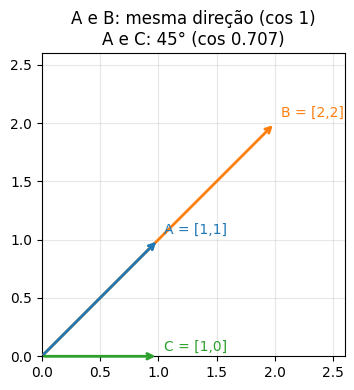

In [6]:
# Verificação do 6.1 -- as definições da página escritas à mão, sem biblioteca
documents = [
    "The mutant superpower was wild and dangerous.",
    "The superpower felt wild and very dangerous.",
    "The Avengers assembled before the battle.",
]
docs3 = [re.findall(r"[a-z]+", d.lower()) for d in documents]
N3 = len(docs3)
def tf(t, d):    return d.count(t) / len(d)
def df_(t, D):   return sum(t in d for d in D)
def idf(t, D=docs3):  return math.log(len(D) / df_(t, D))
def tfidf(t, d, D=docs3): return tf(t, d) * idf(t, D)

print("tamanho dos documentos:", [len(d) for d in docs3])
for t in ["the", "superpower", "mutant"]:
    print(f"{t:11s} df = {df_(t, docs3)}   idf = ln(3/{df_(t, docs3)}) = {idf(t):.4f}")
print(f"\ntfidf(superpower, D1) = (1/7)·{idf('superpower'):.4f} = {tfidf('superpower', docs3[0]):.4f}")
print(f"tfidf(superpower, D2) = (1/7)·{idf('superpower'):.4f} = {tfidf('superpower', docs3[1]):.4f}")
print(f"tfidf(mutant, D1)     = (1/7)·{idf('mutant'):.4f} = {tfidf('mutant', docs3[0]):.4f}")
print(f"tfidf(the, D3)        = (2/7)·{idf('the'):.4f} = {tfidf('the', docs3[2]):.4f}")

def cosine(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
A, B, C = [1, 1], [2, 2], [1, 0]
print(f"\ncos(A,B) = {cosine(A, B):.4f}   cos(A,C) = {cosine(A, C):.4f} (ângulo {np.degrees(np.arccos(cosine(A, C))):.0f}°)"
      f"   cos(10A,B) = {cosine(np.multiply(10, A), B):.4f}")

fig, ax = plt.subplots(figsize=(4, 4))
for v, lbl, col in [(B, "B = [2,2]", "C1"), (A, "A = [1,1]", "C0"), (C, "C = [1,0]", "C2")]:
    ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=2, color=col))
    ax.text(v[0] + 0.05, v[1] + 0.05, lbl, color=col)
ax.set_xlim(0, 2.6); ax.set_ylim(0, 2.6); ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.set_title("A e B: mesma direção (cos 1)\nA e C: 45° (cos 0.707)")
plt.tight_layout(); plt.savefig("figs/6.1_vectors.png", dpi=150); plt.show()

A verificação confirma tudo: df 3/2/1, IDF 0 / 0.4055 / 1.0986, TF-IDF 0.0579 / 0.0579 / 0.1569, *the* em D3 = 0,
cos(A,B) = 1, cos(A,C) = 0.7071 (45°), cos(10A,B) = 1.

## Exercício 6.2 — Document similarity on Marvel, as code (🔬 tool)

> Now scale the same ideas up. Let your agent help with the implementation, but keep the small examples from 6.1 beside you as checks.
>
> 1. Reproduce the three teaching documents in code. Implement the TF, IDF and TF-IDF definitions from this page and verify at least three values against your hand calculations from 6.1.
> 2. Now run scikit-learn's `TfidfVectorizer` on the same three documents. Its numbers will not match yours. Using its documentation and `vectorizer.idf_`, find every choice it makes differently from this page, and find the settings that bring it as close to the page as it will go. Can you make it match exactly?
> 3. Implement cosine similarity once yourself, then compare the result with a library implementation such as `sklearn.metrics.pairwise.cosine_similarity`.
> 4. Build TF-IDF vectors for the 303 Marvel pages. State the preprocessing choices you made before you calculate any similarities.
> 5. Find the five most similar pairs of character pages. Open the underlying text for every pair before you explain why they are close. Find at least one pair where the similarity is driven by something less interesting than shared character meaning, for example repeated Wikipedia phrasing or formatting.
> 6. Pick one character and put three neighbor lists side by side: its closest pages under last week's counts with stopwords removed, its closest pages under your TF-IDF, and its neighbors in the Wikipedia link network. What does each definition of "neighbor" capture that the others miss? Find one match driven by a shared name rather than a shared story, like Storm and the Human Torch.

**6.2.1.** As funções `tf`, `idf`, `tfidf` da célula de verificação do 6.1 **são** a implementação; os três
valores (0.058, 0.058, 0.157) batem com a mão. Abaixo, os vetores completos e os cossenos da página.

In [7]:
# 6.2.1 -- vetores TF-IDF completos para D1–D3 com as definições da página
vocab3 = sorted({t for d in docs3 for t in d})
V3 = np.array([[tfidf(t, d) for t in vocab3] for d in docs3])
print(pd.DataFrame(V3, index=["D1", "D2", "D3"], columns=vocab3).round(3).to_string())
print(f"\ncos(D1,D2) = {cosine(V3[0], V3[1]):.3f}   cos(D1,D3) = {cosine(V3[0], V3[2]):.3f}   cos(D2,D3) = {cosine(V3[1], V3[2]):.3f}")

      and  assembled  avengers  battle  before  dangerous   felt  mutant  superpower  the   very    was   wild
D1  0.058      0.000     0.000   0.000   0.000      0.058  0.000   0.157       0.058  0.0  0.000  0.157  0.058
D2  0.058      0.000     0.000   0.000   0.000      0.058  0.157   0.000       0.058  0.0  0.157  0.000  0.058
D3  0.000      0.183     0.183   0.183   0.183      0.000  0.000   0.000       0.000  0.0  0.000  0.000  0.000

cos(D1,D2) = 0.214   cos(D1,D3) = 0.000   cos(D2,D3) = 0.000


cos(D1,D2) = **0.214** e cos(D1,D3) = **0** — D1 e D3 só partilham *the*, que pesa 0. São os números da página.

In [8]:
# 6.2.2 -- o que o TfidfVectorizer faz de diferente
def sk_report(label, **kw):
    v = TfidfVectorizer(**kw); X_ = v.fit_transform(documents)
    idf_ = dict(zip(v.get_feature_names_out(), v.idf_))
    S = cosine_similarity(X_)
    return dict(definicao=label, idf_the=round(idf_["the"], 3), idf_superpower=round(idf_["superpower"], 3),
                idf_mutant=round(idf_["mutant"], 3), cos_D1D2=round(S[0, 1], 3), cos_D1D3=round(S[0, 2], 3))

rows = [dict(definicao="a página (à mão)", idf_the=round(idf("the"), 3), idf_superpower=round(idf("superpower"), 3),
             idf_mutant=round(idf("mutant"), 3), cos_D1D2=round(cosine(V3[0], V3[1]), 3), cos_D1D3=round(cosine(V3[0], V3[2]), 3)),
        sk_report("TfidfVectorizer() por omissão"),
        sk_report("smooth_idf=False", smooth_idf=False),
        sk_report("smooth_idf=False, norm=None", smooth_idf=False, norm=None),
        sk_report("smooth_idf=False, norm=None, sublinear_tf=True", smooth_idf=False, norm=None, sublinear_tf=True)]
print(pd.DataFrame(rows).to_string(index=False))

v0 = TfidfVectorizer().fit(documents)
X0 = v0.transform(documents).toarray()
print("\npor omissão: norma de cada linha =", np.linalg.norm(X0, axis=1).round(3),
      "| tf usado = contagem bruta? ", TfidfVectorizer(norm=None, use_idf=False).fit_transform(documents).toarray()[2].max())

# igualar EXATAMENTE a página: sem smoothing, sem normalização, tirar o +1 do idf_ e dividir pela dimensão do documento
v_eq = TfidfVectorizer(smooth_idf=False, norm=None).fit(documents)
v_eq.idf_ = v_eq.idf_ - 1                               # o "+1" que nenhuma opção desliga
X_eq = v_eq.transform(documents).toarray()
X_eq = X_eq / np.array([len(d) for d in docs3])[:, None]  # tf = contagem / |d|
page = pd.DataFrame(V3, columns=vocab3)[list(v_eq.get_feature_names_out())].values
print("igual à página, célula a célula?", np.allclose(X_eq, page), "| maior diferença:", np.abs(X_eq - page).max())

                                     definicao  idf_the  idf_superpower  idf_mutant  cos_D1D2  cos_D1D3
                              a página (à mão)      0.0           0.405       1.099     0.214     0.000
                 TfidfVectorizer() por omissão      1.0           1.288       1.693     0.571     0.139
                              smooth_idf=False      1.0           1.405       2.099     0.503     0.102
                   smooth_idf=False, norm=None      1.0           1.405       2.099     0.503     0.102
smooth_idf=False, norm=None, sublinear_tf=True      1.0           1.405       2.099     0.503     0.089

por omissão: norma de cada linha = [1. 1. 1.] | tf usado = contagem bruta?  2.0
igual à página, célula a célula? True | maior diferença: 5.551115123125783e-17


**6.2.2 — O que o `TfidfVectorizer` faz de diferente.** Três escolhas (vistas no `idf_`, na norma das linhas e na documentação):

| | a página | `TfidfVectorizer()` por omissão |
|---|---|---|
| **tf** | contagem / $\lvert d\rvert$ | **contagem bruta** (o *the* de D3 entra com 2) |
| **idf** | $\ln\frac{N}{\mathrm{df}}$ | $\ln\frac{1+N}{1+\mathrm{df}} + 1$ — **smoothing** (+1 como se houvesse um documento extra com todos os termos) **e um +1 no fim** |
| **normalização** | nenhuma | cada linha dividida pela sua norma L2 (`norm="l2"`) |

No `idf_`: *the* = **1.0** (e não 0), *superpower* 1.288, *mutant* 1.693. Por isso D1–D3 passa de 0 para **0.139**: o *the* deixou de pesar zero.

**As opções que mais aproximam:** `smooth_idf=False` → idf = $\ln(N/\mathrm{df}) + 1$ (1.405, 2.099) e D1–D3 desce para
**0.102**. `norm=None` não muda nenhum cosseno (o cosseno ignora o comprimento), e a tf bruta em vez de relativa
também não (dentro de um documento é só multiplicar por $1/\lvert d\rvert$ — o truque do 6.1.4). `sublinear_tf=True`
afasta ainda mais (0.089). **O +1 final não tem opção que o desligue** — está lá para que um termo presente em
todos os documentos "não seja totalmente ignorado".

**Igualar exatamente:** `smooth_idf=False, norm=None`, depois **subtrair 1 ao `idf_`** à mão e dividir cada
linha pelo comprimento do documento → célula a célula igual à página (maior diferença $5.6\times10^{-17}$, erro
de arredondamento). A lição é a da semana 5 com o `CountVectorizer`: a biblioteca faz escolhas, e só se veem
quando se compara o resultado com um caso feito à mão.

In [9]:
# 6.2.3 -- o meu cosseno contra o do sklearn (nas 3 frases e em 303 páginas)
mine = np.array([[cosine(a, b) for b in V3] for a in V3])
print("3 frases, maior diferença:", np.abs(mine - cosine_similarity(V3)).max())

3 frases, maior diferença: 1.1102230246251565e-16


**6.2.3.** O meu cosseno e o do scikit-learn coincidem nas 3 frases (diferença $1.1\times10^{-16}$) e, na célula
seguinte, nas 303 páginas (diferença 0.0).

In [10]:
# 6.2.4 -- TF-IDF (definições da página) para as 303 páginas
# ESCOLHAS, declaradas antes de calcular semelhanças:
#   documento = uma página completa da Wikipédia; tokens = tokenizer por omissão do CountVectorizer
#   (minúsculas, sequências de >= 2 letras/dígitos -- parte "X-Men" em "men" e deita fora o "x");
#   SEM lista de stopwords (é o IDF que tem de tratar delas); sem lematização; sem filtro de frequência.
#   tf = contagem / nº de tokens da página;  idf = ln(N / df).
cv = CountVectorizer()
Xc = cv.fit_transform(texts).astype(float)               # 303 × V, esparsa
terms = cv.get_feature_names_out(); tix = cv.vocabulary_
doc_len = np.asarray(Xc.sum(1)).ravel()
df_t = np.asarray((Xc > 0).sum(0)).ravel()
idf_t = np.log(len(IDS) / df_t)
X_tfidf = sparse.csr_matrix(sparse.diags(1 / doc_len) @ Xc @ sparse.diags(idf_t))
print(f"matriz TF-IDF: {X_tfidf.shape}, {X_tfidf.nnz:,} células não nulas")
print("termos presentes nas 303 páginas (idf = 0):", ", ".join(terms[df_t == len(IDS)]))
for w in ["the", "marvel", "comics", "mutant", "storm", "adamantium", "symbiote"]:
    print(f"  {w:10s} df = {df_t[tix[w]]:3d}  idf = {idf_t[tix[w]]:.3f}")

S_tfidf = cosine_similarity(X_tfidf)
mine_303 = (normalize(X_tfidf) @ normalize(X_tfidf).T).toarray()
print("303 páginas, o meu cosseno (normalizar + produto interno) vs sklearn, maior diferença:", np.abs(mine_303 - S_tfidf).max())

matriz TF-IDF: (303, 26279), 232,229 células não nulas
termos presentes nas 303 páginas (idf = 0): and, by, character, comics, in, is, marvel, of, the, to
  the        df = 303  idf = 0.000
  marvel     df = 303  idf = 0.000
  comics     df = 303  idf = 0.000
  mutant     df =  97  idf = 1.139
  storm      df =  44  idf = 1.930
  adamantium df =  14  idf = 3.075
  symbiote   df =  32  idf = 2.248
303 páginas, o meu cosseno (normalizar + produto interno) vs sklearn, maior diferença: 0.0


**6.2.4 — Escolhas, declaradas antes das semelhanças:** documento = uma página completa; tokens do
`CountVectorizer` por omissão (minúsculas, ≥ 2 letras/dígitos — *X-Men* vira *men*, *K'un-Lun* vira *un* + *lun*);
**sem** lista de stopwords; sem lematização; sem filtro de frequência; tf e idf da página.

Resultado: matriz $303 \times 26\,279$. **Dez termos têm idf = 0** porque estão nas 303 páginas: *and, by,
character, comics, in, is, marvel, of, the, to* — é a frase de abertura da Wikipédia (*"… is a character
appearing in American comic books published by Marvel Comics"*) e o IDF apaga-a sozinho. *mutant* (97 páginas)
1.14; *storm* (44) 1.93; *adamantium* (14) 3.07.

In [11]:
# 6.2.5 -- os pares mais semelhantes, com os termos que levam a semelhança
Xn = normalize(X_tfidf)
def top_shared(i, j, k=6):
    contrib = Xn[i].multiply(Xn[j]).toarray().ravel()        # cos = soma destas contribuições
    idx = contrib.argsort()[::-1][:k]
    return ", ".join(f"{terms[t]} {contrib[t] / contrib.sum():.0%}" for t in idx)

iu = np.triu_indices(len(IDS), 1)
order = np.argsort(S_tfidf[iu])[::-1]
pairs = pd.DataFrame([dict(a=name[IDS[iu[0][o]]], b=name[IDS[iu[1][o]]], cos=round(S_tfidf[iu][o], 3),
                           ligadas=(IDS[iu[0][o]], IDS[iu[1][o]]) in linked,
                           termos=top_shared(iu[0][o], iu[1][o]))
                      for o in order[:12]])
print(pairs.to_string(index=False))
print(f"\ncosseno médio entre dois pares quaisquer: TF-IDF {S_tfidf[iu].mean():.3f}")

                                    a                                 b   cos  ligadas                                                                     termos
                          Eddie Brock                 Venom (character) 0.867     True       venom 30%, brock 29%, symbiote 14%, eddie 14%, spider 3%, carnage 1%
                          Ghost Rider        Ghost Rider (Johnny Blaze) 0.776     True         rider 27%, ghost 26%, blaze 25%, johnny 9%, ketch 3%, vengeance 1%
                            Jean Grey Phoenix (Guardians of the Galaxy) 0.703     True               phoenix 55%, jean 26%, grey 7%, cyclops 2%, force 1%, men 1%
        White Tiger (Heroes for Hire)              White Tiger (comics) 0.681     True            tiger 76%, white 9%, ayala 3%, tigress 2%, hector 2%, bengal 1%
                            Killpower               Motormouth (comics) 0.681     True        killpower 54%, motormouth 37%, mys 4%, tech 2%, moped 1%, scream 0%
                            

In [12]:
# abrir o texto de cada par (primeiros 300 caracteres + uma passagem com o termo mais partilhado)
def snippet(pid, term, width=110):
    s = marvel_pages[pid]; m = re.search(rf"\b{re.escape(term)}\b", s, flags=re.I)
    if not m: return "(termo não encontrado)"
    a = max(0, m.start() - width // 2); return "…" + s[a:a + width].replace("\n", " ") + "…"
inv = {v: k for k, v in name.items()}
for o in order[:5]:
    i, j = iu[0][o], iu[1][o]
    contrib = Xn[i].multiply(Xn[j]).toarray().ravel(); t = terms[contrib.argmax()]
    print(f"■ {name[IDS[i]]}  ×  {name[IDS[j]]}   (termo principal: '{t}')")
    for k in (i, j):
        print(f"   {name[IDS[k]]:28s} {len(marvel_pages[IDS[k]]):6,} car. | {marvel_pages[IDS[k]][:150].replace(chr(10), ' ')}…")
        print(f"   {'':28s} {snippet(IDS[k], t)}")

■ Eddie Brock  ×  Venom (character)   (termo principal: 'venom')
   Eddie Brock                  63,379 car. | Edward Charles Allan Brock is a character appearing in American comic books published by Marvel Comics. The character was created by David Michelinie …
                                …Man #300 (May 1988) as the most well-known host of the Venom symbiote. The character has since appeared in man…
   Venom (character)            63,732 car. | Venom, known formally as "the Symbiote", is a character appearing in American comic books published by Marvel Comics. The character is a sentient alie…
                                …Venom, known formally as "the Symbiote", is a character appearing in American comic books published by Marvel …
■ Ghost Rider  ×  Ghost Rider (Johnny Blaze)   (termo principal: 'rider')
   Ghost Rider                  42,301 car. | Ghost Rider is the name of multiple superheroes appearing in American comic books published by Marvel Comics.  Marvel had previou

**6.2.5 — Os cinco pares mais semelhantes**, depois de abrir as páginas:

| par | cos | o que o texto mostra |
|---|---:|---|
| Eddie Brock × Venom | 0.867 | o hospedeiro e o simbionte: a página de Eddie Brock diz *"the most well-known host of the Venom symbiote"*; a de Venom começa *"known formally as 'the Symbiote'"*. Partilham *venom, brock, symbiote, eddie* — a mesma história contada duas vezes. |
| Ghost Rider × Ghost Rider (Johnny Blaze) | 0.776 | a página-chapéu (*"the name of multiple superheroes"*) e a página de um dos portadores: *rider, ghost, blaze*. |
| Jean Grey × Phoenix (Guardians of the Galaxy) | 0.703 | a Phoenix Force é a entidade cósmica que a Jean Grey hospeda (*"physical manifestation of the cosmic entity known as the Phoenix Force"*): *phoenix* 55%, *jean* 26%. |
| White Tiger (Heroes for Hire) × White Tiger (comics) | 0.681 | **mesmo nome, personagens diferentes**: a primeira é um *"fictional animal superhero"*; a segunda é *"the name of several superheroes"*. 76% da semelhança é o termo *tiger*. |
| Killpower × Motormouth | 0.681 | uma dupla: Motormouth teve a série *"Motormouth (later Motormouth & Killpower)"*; páginas curtas que se citam pelo nome. |

Todos os cinco pares estão ligados na rede, e em todos os termos que levam a semelhança são **nomes**. O
TF-IDF premeia o raro, e nada é tão raro como um nome próprio — por isso, nas páginas da Wikipédia, "semelhante"
quer dizer sobretudo "fala das mesmas pessoas".

In [13]:
# pares levados por algo menos interessante do que o significado: (a) um número, (b) um pedaço de palavra
seen, capitalized = Counter(), Counter()
for text in texts:
    for w in re.findall(r"[A-Za-z]+", text):
        seen[w.lower()] += 1; capitalized[w.lower()] += w[0].isupper()
proper = {w for w in seen if capitalized[w] > seen[w] / 2}            # critério da página (Secção 3): maioritariamente com maiúscula = nome
is_num = np.array([t.isdigit() for t in terms])
rows = []
for o in order[:400]:                                                   # os 400 pares mais semelhantes
    i, j = iu[0][o], iu[1][o]
    contrib = Xn[i].multiply(Xn[j]).toarray().ravel(); tot = contrib.sum()
    rows.append(dict(a=name[IDS[i]], b=name[IDS[j]], cos=round(S_tfidf[i, j], 3), ligadas=(IDS[i], IDS[j]) in linked,
                     pct_numeros=round(contrib[is_num].sum() / tot, 2), termos=top_shared(i, j, 6)))
rows = pd.DataFrame(rows)
print("(a) pares em que um NÚMERO leva a semelhança:")
print(rows.sort_values("pct_numeros", ascending=False).head(4).to_string(index=False))
print("\n(b) pares em que pedaços de palavras partidas no apóstrofo/hífen (K'un-Lun -> 'un', 'lun'; Shi'ar -> 'shi', 'ar') levam a semelhança:")
FRAG = ["un", "lun", "shi", "ar", "od", "ch"]
fr = []
for o in order[:400]:
    i, j = iu[0][o], iu[1][o]
    contrib = Xn[i].multiply(Xn[j]).toarray().ravel()
    fr.append(round(sum(contrib[tix[f]] for f in FRAG if f in tix) / contrib.sum(), 2))
rows["pct_fragmentos"] = fr
print(rows.sort_values("pct_fragmentos", ascending=False).head(4).drop(columns="pct_numeros").to_string(index=False))
hk = [n for n in IDS if name[n] == "Hawkeye (comics)"][0]
print("\nHawkeye (comics):", snippet(hk, "2099", 160))
cm = [n for n in IDS if name[n] == "Crane Mother"][0]
print("Crane Mother    :", snippet(cm, "Un", 120))

(a) pares em que um NÚMERO leva a semelhança:
               a                b   cos  ligadas  pct_numeros                                                                     termos
Hawkeye (comics)        Hulk 2099 0.155    False         0.96          2099 96%, unified 1%, unlike 0%, wars 0%, reality 0%, avengers 0%
       Doom 2099 Hawkeye (comics) 0.143    False         0.94 2099 94%, bishop 2%, richards 0%, unidentified 0%, assisted 0%, reality 0%
       Doom 2099        Hulk 2099 0.299     True         0.88           2099 88%, doom 2%, timestorm 2%, proteus 2%, hulk 1%, knights 1%
       Doom 2099      Ravage 2099 0.151     True         0.67           2099 66%, ravage 12%, doom 9%, hellrock 3%, alchemax 1%, stan 1%

(b) pares em que pedaços de palavras partidas no apóstrofo/hífen (K'un-Lun -> 'un', 'lun'; Shi'ar -> 'shi', 'ar') levam a semelhança:
                  a                      b   cos  ligadas                                                           termos  pct_fragme

**Pares levados por algo menos interessante do que o significado** (procurei nos 400 pares mais semelhantes):

- **Um número.** *Hawkeye (comics)* × *Hulk 2099*: cos 0.155, **não ligados**, e **96%** da semelhança é o token
  `2099`. A página do Hawkeye tem uma secção *"Marvel 2099 — There have been two versions of Hawkeye in Marvel
  2099"*; *2099* aparece em poucas páginas, logo tem idf alto, e não há mais nada em comum. O mesmo com *Doom 2099*
  × *Hawkeye* (94%). É o nome de uma linha editorial a fazer de "tema".
- **Pedaços de palavras fabricados pelo tokenizer.** *Gladiator (Kallark)* × *Korvus*: 72% da semelhança vem de
  `ar` e `shi` — é *Shi'ar* partido no apóstrofo (o token pattern exige 2+ letras e parte em `'`). *Crane Mother* ×
  *Lei Kung*: 50% vem de `un`, de *K'un-Lun* / *K'un-Zi* partidos no apóstrofo e no hífen. A semelhança
  é real (o império Shi'ar, a cidade de K'un-Lun), mas o que a mede é um artefacto de formatação — e `un`, `ar`
  sozinhos nunca entrariam numa lista de palavras com sentido.

In [14]:
# 6.2.6 -- três definições de "vizinho" para a mesma personagem
X_ns = CountVectorizer(stop_words="english").fit_transform(texts)       # a da semana 5: contagens sem stopwords
S_ns = cosine_similarity(X_ns)
def neigh(pid, S, k=8):
    q = IDS.index(pid); s = S[q].copy(); s[q] = -1
    return [(name[IDS[j]] + (" ●" if (pid, IDS[j]) in linked else "")) for j in s.argsort()[::-1][:k]]
P = "Storm_(Marvel_Comics)" if "Storm_(Marvel_Comics)" in IDS else [i for i in IDS if i.startswith("Storm")][0]
net = sorted(G[P], key=lambda n: -deg[n])
tab = pd.DataFrame({"contagens sem stopwords (sem. 5)": neigh(P, S_ns), "TF-IDF (esta semana)": neigh(P, S_tfidf),
                    "vizinhos na rede (por grau)": [name[n] for n in net[:8]] + [""] * max(0, 8 - len(net))})
print(f"{name[P]} — {len(net)} vizinhos na rede; ● = ligada na rede\n")
print(tab.to_string(index=False))

def frac_linked(S, k=10):
    hits = 0
    for q in range(len(IDS)):
        s = S[q].copy(); s[q] = -1
        hits += sum((IDS[q], IDS[j]) in linked for j in s.argsort()[::-1][:k])
    return hits / len(IDS)
X_raw = CountVectorizer().fit_transform(texts)
print(f"\ndos 10 vizinhos textuais, quantos estão ligados na rede (média por página): "
      f"contagens brutas {frac_linked(cosine_similarity(X_raw)):.1f} | sem stopwords {frac_linked(S_ns):.1f} | "
      f"TF-IDF {frac_linked(S_tfidf):.1f} | 10 páginas ao acaso {10 * len(linked) / (len(IDS) * (len(IDS) - 1)):.1f}")

ht = IDS.index([i for i in IDS if name[i] == "Human Torch"][0]); st_ = IDS.index(P)
print(f"\n{name[P]} × Human Torch: cos TF-IDF {S_tfidf[st_, ht]:.3f}; termos: {top_shared(st_, ht, 6)}")
print("passagem na página do Human Torch:", snippet(IDS[ht], "Storm"))

Storm (Marvel Comics) — 27 vizinhos na rede; ● = ligada na rede

contagens sem stopwords (sem. 5)                    TF-IDF (esta semana)       vizinhos na rede (por grau)
       Cyclops (Marvel Comics) ●                             Human Torch                        Spider-Man
     Black Panther (character) ●             Black Panther (character) ●             Wolverine (character)
                     Human Torch               Cyclops (Marvel Comics) ●                    Doctor Strange
                     Jean Grey ●                             Jean Grey ● Phoenix (Guardians of the Galaxy)
               Anole (character)                 Wolverine (character) ●                     Scarlet Witch
           Surge (Marvel Comics) Wolverine (Ultimate Marvel character) ●         Black Panther (character)
                  Oya (comics) ●                            Emma Frost ●                    Betsy Braddock
                    Fabio Medina                     Shuri (character) ●       

**6.2.6 — Três definições de "vizinho" para a Storm** (● = ligada na rede):

- **Contagens sem stopwords (semana 5):** Cyclops, Black Panther, **Human Torch**, Jean Grey, Anole, Surge, Oya,
  Fabio Medina — 4 de 8 ligadas. Apanha "páginas que usam o mesmo vocabulário de X-Men" (*mutant, x, men*), por isso
  traz X-Men jovens e pouco ligados (Anole, Surge, Fabio Medina). As palavras frequentes de conteúdo dominam.
- **TF-IDF:** Human Torch, Black Panther ●, Cyclops ●, Jean Grey ●, Wolverine ●, Wolverine Ultimate ●, Emma Frost ●,
  Shuri ● — **7 de 8 ligadas**. O TF-IDF valoriza o que é *raro e partilhado*: o marido (T'Challa), a cunhada
  (Shuri), a equipa nuclear dos X-Men. Apanha a **história** pessoal melhor do que as contagens.
- **Rede:** os vizinhos de maior grau são Spider-Man, Wolverine, Doctor Strange, Phoenix, Scarlet Witch… — os hubs
  para onde a página aponta (ou de onde é apontada), incluindo ligações que o texto quase não desenvolve (Spider-Man,
  Doctor Strange). Apanha **com quem a página se liga**, não sobre o que fala; e nunca devolveria um par que o
  texto aproxima sem ligação.

Em média, dos 10 vizinhos textuais de uma página, estão ligados na rede: **1.8** com contagens brutas, **2.8**
sem stopwords, **4.0** com TF-IDF e **0.3** com 10 páginas ao acaso — os números da página.

**Um par por nome, não por história:** **Storm × Human Torch**, cos 0.329 — o maior vizinho TF-IDF da Storm, e
**não** ligado na rede. **87%** da semelhança é o termo *storm*: o Human Torch é *"Jonathan Lowell Spencer 'Johnny'
Storm"*. Um apelido é uma palavra rara, e o TF-IDF não distingue um nome de um significado. Outro do mesmo
género, do 6.2.5: os dois White Tiger (o *tiger* é um nome de código partilhado por personagens diferentes).

---
## 📘 Exemplo da página — Secção 2 · Compare groups of documents

**O código que refaz a figura de ensino** (discursos das convenções de 2012, que vêm dentro do pacote
`scattertext`). Escreve `conventions.html` na pasta do notebook: abre-o no browser. Para a Marvel, diz a página,
só muda a DataFrame — uma linha por página, a coluna de texto e a comunidade como categoria — que é o que o 6.3 faz.

In [21]:
import sys
print(sys.executable)
%pip install --no-deps scattertext flashtext

c:\Users\carlo\miniforge3\envs\dtu02452\python.exe
  Using cached scattertext-0.2.2-py3-none-any.whl.metadata (581 bytes)
  Using cached flashtext-2.7-py2.py3-none-any.whl
Using cached scattertext-0.2.2-py3-none-any.whl (9.4 MB)

   -------------------- ------------------- 1/2 [scattertext]
   -------------------- ------------------- 1/2 [scattertext]
   -------------------- ------------------- 1/2 [scattertext]
   -------------------- ------------------- 1/2 [scattertext]
   -------------------- ------------------- 1/2 [scattertext]
   -------------------- ------------------- 1/2 [scattertext]
   -------------------- ------------------- 1/2 [scattertext]
   -------------------- ------------------- 1/2 [scattertext]
   -------------------- ------------------- 1/2 [scattertext]
   -------------------- ------------------- 1/2 [scattertext]
   -------------------- ------------------- 1/2 [scattertext]
   -------------------- ------------------- 1/2 [scattertext]
   -------------------- --


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
%conda install -y -c conda-forge statsmodels

Retrieving notices: done
Solving environment: done

## Package Plan ##

  environment location: c:\Users\carlo\miniforge3\envs\dtu02452

  added / updated specs:
    - statsmodels


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    ca-certificates-2026.7.22  |       h4c7d964_0         129 KB  conda-forge
    formulaic-1.2.2            |     pyhd8ed1ab_0          88 KB  conda-forge
    interface_meta-1.3.0       |     pyhd8ed1ab_1          18 KB  conda-forge
    libhwloc-2.13.0            |default_h8af1a8b_1000         2.3 MB
    libiconv-1.18              |       hc1393d2_3         679 KB  conda-forge
    libxml2-2.13.9             |       h6201b9f_0         1.5 MB
    llvm-openmp-23.1.3         |       h49e36cd_1         336 KB  conda-forge
    mkl-2025.3.1               |      hac47afa_11        95.4 MB  conda-forge
    mkl-service-2.9.0          |  py312h1b35211_0         114 KB
    mkl



==> WARNING: A newer version of conda exists. <==
  current version: 24.11.3
  latest version: 26.9.3

Please update conda by running

    $ conda update -n base -c defaults conda

Or to minimize the number of packages updated during conda update use

     conda install conda=26.9.3




In [24]:
import scattertext as st

df = st.SampleCorpora.ConventionData2012.get_data()   # 189 speeches: party, text, speaker
corpus = st.CorpusFromPandas(
    df, category_col="party", text_col="text",
    nlp=st.whitespace_nlp_with_sentences,
).build()

html = st.produce_scattertext_explorer(
    corpus, category="democrat",
    category_name="Democratic", not_category_name="Republican",
    metadata=df["speaker"], width_in_pixels=1000,
)
open("conventions.html", "w").write(html)

1608532

O número que aparece acima é o número de caracteres escritos no ficheiro (é o que `write()` devolve). Uma
verificação rápida do corpus:

In [25]:
print(len(df), "discursos |", df.party.value_counts().to_dict())

189 discursos | {'democrat': 123, 'republican': 66}


## Exercício 6.3 — Compare two corpora with Scattertext (🔬 tool)

> Use the Marvel data and make the comparison your own. The package can do the bookkeeping; the interpretation is still yours.
>
> 1. Before you build anything, explain how the teaching figure above is set up. What does one dot represent? What do the horizontal and vertical axes measure? What does the diagonal mean, and why are the axes log-scaled?
> 2. Choose two reasonably large structural communities from the Marvel network (Louvain, as in week 4, run on the week 1 network). Before you run anything, write down three words or phrases you expect to distinguish them and why.
> 3. Build a Scattertext comparison of the text from those two communities. Start with scattertext, but feel free to use your favorite agent to change the layout, labels or interaction if you can make the result easier to read. If you would rather recreate the core comparison yourself, that is also fine, as long as you can explain what your axes and term positions mean.
> 4. Find three terms close to the diagonal and three terms clearly pulled toward one community. For each distinctive term, open at least one page where it occurs and decide whether the term really tells you something about the community.
> 5. Find one term that initially looks informative but becomes less convincing after you inspect the underlying pages. What created the misleading signal?
> 6. Change one modeling or display choice, for example the minimum term frequency, whether repeated uses within a document count, or which terms are labeled. Which conclusions stay the same and which change?
> 7. Finish with two sentences: what question does your Scattertext figure answer well, and what question can it not answer from word frequencies alone?

### 6.3.1 — Como a figura de ensino está montada

- **Um ponto = um termo** (palavra ou frase) do corpus das convenções de 2012.
- **Eixo horizontal:** quantas vezes o termo é usado nos discursos **republicanos**, por 10 000 palavras.
  **Eixo vertical:** o mesmo nos discursos **democratas**. São taxas, não contagens, para os dois grupos serem
  comparáveis apesar de terem tamanhos diferentes.
- **A diagonal:** os pontos onde as duas taxas são iguais — termos usados ao mesmo ritmo pelos dois partidos.
  Acima da diagonal: relativamente mais democrata; abaixo: mais republicano. Quanto mais longe da diagonal, mais
  distintivo; quanto mais longe da origem, mais frequente.
- **Eixos em log:** as frequências das palavras têm cauda pesada (Zipf, semana 5). Em eixos lineares, *the* e
  *and* esticariam a escala e milhares de termos raros ficariam esmagados num canto; em log espalham-se, e a
  distância à diagonal passa a ler-se como uma **razão** de taxas (um ponto 1 década acima = 10× mais usado por um grupo).

In [26]:
# 6.3.2 -- as duas comunidades (Louvain seed 0 na rede da semana 1, como na semana 4)
for k in range(4):
    c = P_louvain[k]; top = sorted(c, key=lambda n: -deg[n])[:8]
    print(f"C{k} ({len(c)} páginas, {sum(doc_len[IDS.index(n)] for n in c):,.0f} tokens): " + ", ".join(name[n] for n in top))
CA, CB = 0, 5                     # X-Men  vs  o grupo sobrenatural de Doctor Strange
c5 = P_louvain[CB]; print(f"\nC{CB} ({len(c5)} páginas, {sum(doc_len[IDS.index(n)] for n in c5):,.0f} tokens): "
                         + ", ".join(name[n] for n in sorted(c5, key=lambda n: -deg[n])[:10]))
LAB = {CA: "X-Men", CB: "Sobrenatural"}

C0 (44 páginas, 136,319 tokens): Wolverine (character), Scarlet Witch, Phoenix (Guardians of the Galaxy), Betsy Braddock, Storm (Marvel Comics), Emma Frost, Cyclops (Marvel Comics), Jean Grey
C1 (40 páginas, 96,496 tokens): She-Hulk, Black Panther (character), Hank Pym, Black Widow (Natasha Romanova), Mockingbird (Marvel Comics), Shang-Chi, Bill Foster (character), War Machine
C2 (39 páginas, 83,394 tokens): Hercules (Marvel Comics), Adam Warlock, Quasar (character), Noh-Varr, Star-Lord, Captain Universe, Captain Marvel (Marvel Comics), Rocket Raccoon
C3 (36 páginas, 102,756 tokens): Spider-Man, Venom (character), Black Cat (Marvel Comics), Eddie Brock, Spider-Woman (Jessica Drew), Spider-Woman (Gwen Stacy), Mayday Parker, Spider-Woman

C5 (33 páginas, 96,581 tokens): Doctor Strange, Deadpool, Moon Knight, Ghost Rider, Blade (character), Man-Thing, Morbius, Jericho Drumm, Werewolf by Night, Ghost Rider (Johnny Blaze)


### 6.3.2 — As duas comunidades e as previsões (escritas antes de correr a comparação)

**C0 — X-Men** (44 páginas, ≈136 000 tokens: Wolverine, Phoenix, Scarlet Witch, Betsy Braddock, Emma Frost,
Storm, Cyclops, Jean Grey) contra **C5 — Sobrenatural** (33 páginas, ≈97 000 tokens: Doctor Strange, Deadpool,
Moon Knight, Ghost Rider, Blade, Man-Thing, Morbius, Elsa Bloodstone).

Três termos que espero que as distingam, e porquê:

1. ***mutant / mutants*** → X-Men. É a premissa da franquia ("a team of mutant heroes").
2. ***magic / demon*** → sobrenatural. Doctor Strange é o *Sorcerer Supreme*, Ghost Rider tem um demónio.
3. ***vampire*** → sobrenatural. Blade e Morbius são definidos por vampiros.

E uma previsão negativa: as palavras de função e o molde da Wikipédia (*the, of, published, appearances*) devem
ficar na diagonal.

In [27]:
# 6.3.3 -- Scattertext (o HTML interativo vai para figs/) + a mesma comparação refeita à mão
import scattertext as st
sub = pd.DataFrame([dict(node_id=n, name=name[n], text=marvel_pages[n], community=LAB[comm_of[n]])
                    for n in IDS if comm_of[n] in (CA, CB)])
corpus = st.CorpusFromPandas(sub, category_col="community", text_col="text",
                             nlp=st.whitespace_nlp_with_sentences).build()
html = st.produce_scattertext_explorer(corpus, category="X-Men", category_name="X-Men", not_category_name="Sobrenatural",
                                       metadata=sub["name"], width_in_pixels=1000, minimum_term_frequency=10)
open("figs/6.3_scattertext_xmen_vs_supernatural.html", "w", encoding="utf-8").write(html)
print("figs/6.3_scattertext_xmen_vs_supernatural.html:", f"{len(html) / 1e6:.1f} MB")

# a versão "à mão": contar, passar a taxas por 10 000 palavras, uma taxa contra a outra
cvs = CountVectorizer(token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z'-]+\b")
Xs = cvs.fit_transform(sub.text); vs = cvs.get_feature_names_out()
isA = (sub.community == "X-Men").values
cA = np.asarray(Xs[isA].sum(0)).ravel(); cB = np.asarray(Xs[~isA].sum(0)).ravel()
dA = np.asarray((Xs[isA] > 0).sum(0)).ravel(); dB = np.asarray((Xs[~isA] > 0).sum(0)).ravel()
rA, rB = 1e4 * cA / cA.sum(), 1e4 * cB / cB.sum()
sc = pd.DataFrame(dict(term=vs, nA=cA, nB=cB, docsA=dA, docsB=dB, rateA=rA, rateB=rB))
sc = sc[(sc.nA + sc.nB) >= 10].copy()
eps = 0.5 * 1e4 / max(cA.sum(), cB.sum())                              # meia ocorrência: evita log(0)
sc["log_ratio"] = np.log2((sc.rateA + eps) / (sc.rateB + eps))         # > 0: mais X-Men; < 0: mais sobrenatural
proper_like = {t for t in sc.term if re.sub(r"'s$", "", t).split("-")[0] in proper or "'" in t}   # nomes (critério da página) e formas com apóstrofo
print(f"palavras: X-Men {cA.sum():,} | Sobrenatural {cB.sum():,}; termos com >= 10 usos: {len(sc):,}")

figs/6.3_scattertext_xmen_vs_supernatural.html: 2.7 MB
palavras: X-Men 133,247 | Sobrenatural 93,352; termos com >= 10 usos: 2,680


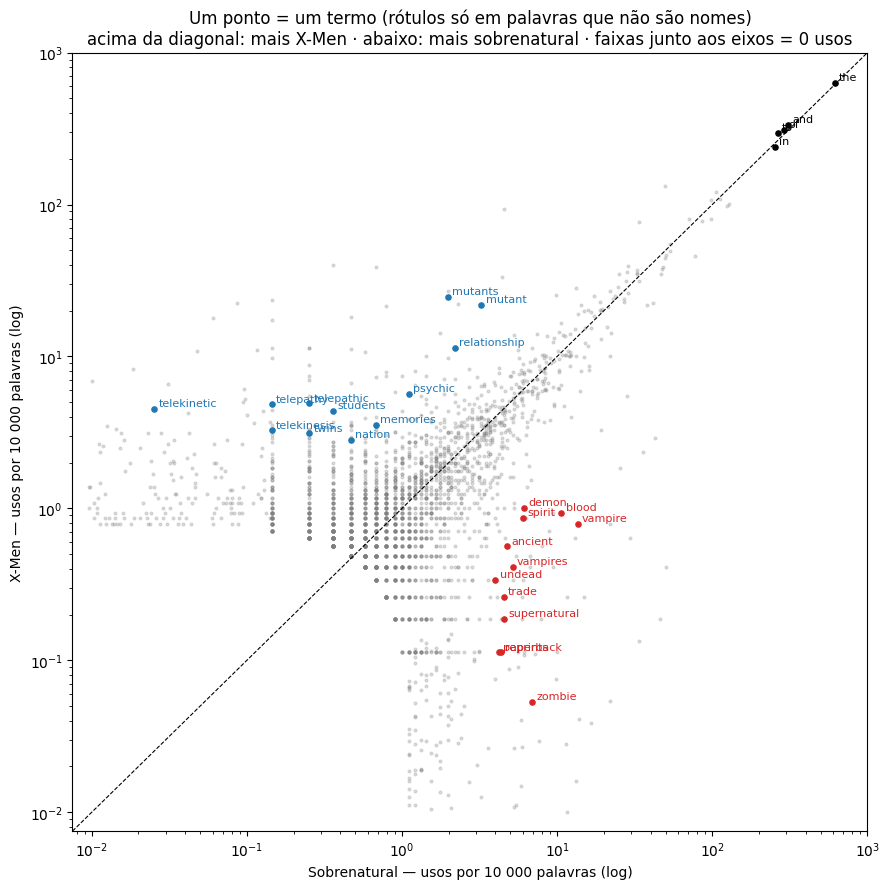

In [28]:
fig, ax = plt.subplots(figsize=(9, 9))
rng = np.random.default_rng(0)
# termos com 0 usos num grupo ficam todos no mesmo valor eps; espalho-os numa faixa (só para se lerem) -- a faixa = "zero"
jx = np.where(sc.nB == 0, eps * 10 ** rng.uniform(-0.6, 0.6, len(sc)), sc.rateB + eps)
jy = np.where(sc.nA == 0, eps * 10 ** rng.uniform(-0.6, 0.6, len(sc)), sc.rateA + eps)
sc["px"], sc["py"] = jx, jy
ax.scatter(sc.px, sc.py, s=4, alpha=0.25, color="gray")
content = sc[(sc.nA + sc.nB >= 40) & ~sc.term.isin(proper_like)]              # rótulos só para palavras que NÃO são nomes
lab = pd.concat([content.nlargest(12, "log_ratio"), content.nsmallest(12, "log_ratio"),
                 sc.nlargest(6, "nA").query("abs(log_ratio) < 0.5")])
for _, r in lab.iterrows():
    col = "C0" if r.log_ratio > 1 else ("C3" if r.log_ratio < -1 else "k")
    ax.scatter(r.px, r.py, s=14, color=col)
    ax.annotate(r.term, (r.px, r.py), xytext=(3, 2), textcoords="offset points", fontsize=8, color=col)
lim = [eps * 0.2, 1e3]; ax.plot(lim, lim, "k--", lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Sobrenatural — usos por 10 000 palavras (log)"); ax.set_ylabel("X-Men — usos por 10 000 palavras (log)")
ax.set_title("Um ponto = um termo (rótulos só em palavras que não são nomes)\nacima da diagonal: mais X-Men · abaixo: mais sobrenatural · faixas junto aos eixos = 0 usos")
plt.tight_layout(); plt.savefig("figs/6.3_two_communities.png", dpi=150); plt.show()

**6.3.3.** O explorador interativo do Scattertext ficou em `figs/6.3_scattertext_xmen_vs_supernatural.html`
(abrir no browser; `minimum_term_frequency=10`). A figura acima é a mesma comparação refeita à mão, para ter a
certeza do que os eixos são: contei cada termo nos dois grupos (token = palavra com ≥ 2 letras, apóstrofos e
hífenes mantidos), passei a **usos por 10 000 palavras** em cada grupo, desenhei uma taxa contra a outra em log, e
somei meia ocorrência a todos para os termos com 0 num grupo não irem para $-\infty$ (e espalhei esses numa faixa junto
ao eixo, só para se lerem). A distância à diagonal é o $\log_2$ da razão das taxas. **Rótulos só em palavras que não
são nomes** (critério da página do 6.5): rotulando os extremos sem filtro, só apareciam nomes (ver a tabela abaixo).

O que a figura mostra: do lado **X-Men**, o vocabulário dos poderes mentais e da escola — *telekinetic, telepathy,
telepathic, telekinesis, psychic, mutant(s), students, memories, nation* (Krakoa); do lado **sobrenatural**, *zombie,
supernatural, vampire(s), undead, blood, demon, spirit, ancient* — e também ***reprints, paperback, trade***, que não são
um tema mas um **formato**: as personagens de horror dos anos 70 têm secções longas sobre as reedições em *trade
paperback*. Na diagonal, em cima à direita, a gramática (*the, and, of, to, in*).

In [29]:
# 6.3.4 -- três perto da diagonal, três puxados para cada lado (só termos com >= 40 usos)
big = sc[sc.nA + sc.nB >= 40]
show = lambda d: d[["term", "nA", "nB", "docsA", "docsB", "rateA", "rateB", "log_ratio"]].round(2).to_string(index=False)
print("perto da diagonal (|log2 ratio| pequeno, frequentes):\n" + show(big[big.log_ratio.abs() < 0.15].nlargest(6, "nA")))
print("\npuxados para X-Men:\n" + show(big.nlargest(10, "log_ratio")))
print("\npuxados para o sobrenatural:\n" + show(big.nsmallest(10, "log_ratio")))

def where(term, mask, k=4):
    rows_ = [(name[n], len(re.findall(rf"\b{re.escape(term)}\b", marvel_pages[n], flags=re.I)))
             for n in sub.node_id[mask]]
    rows_ = sorted([r for r in rows_ if r[1] > 0], key=lambda r: -r[1])
    tot = sum(r[1] for r in rows_)
    return f"'{term}': {tot} usos em {len(rows_)} páginas; maiores: " + ", ".join(f"{a} {b} ({b / tot:.0%})" for a, b in rows_[:k])

perto da diagonal (|log2 ratio| pequeno, frequentes):
term   nA   nB  docsA  docsB  rateA  rateB  log_ratio
 the 8397 5766     44     33 630.18 617.66       0.03
 and 4448 2862     44     33 333.82 306.58       0.12
  of 4138 2714     44     33 310.55 290.73       0.10
  in 3193 2378     44     33 239.63 254.73      -0.09
  as 1453 1054     44     33 109.05 112.91      -0.05
with 1430  912     44     32 107.32  97.69       0.14

puxados para X-Men:
     term  nA  nB  docsA  docsB  rateA  rateB  log_ratio
    betsy 298   0      3      0  22.36   0.00       9.22
    wanda 237   0      2      0  17.79   0.00       8.89
northstar 147   0      6      0  11.03   0.00       8.20
   xavier 144   0     23      0  10.81   0.00       8.17
  hellion 110   0      6      0   8.26   0.00       7.79
   shi'ar  92   0     13      0   6.90   0.00       7.53
   vulcan  87   0      7      0   6.53   0.00       7.45
    anole  81   0      6      0   6.08   0.00       7.35
  cyclops 311   1     26      1  2

In [30]:
for t in ["mutant", "mutants", "school"]: print("X-Men  |", where(t, isA))
for t in ["demon", "magic", "vampire", "soul"]: print("Sobren.|", where(t, ~isA))
print()
print(snippet([n for n in IDS if name[n] == "Doctor Strange"][0], "magic"))
print(snippet([n for n in IDS if name[n] == "Cyclops (Marvel Comics)"][0], "mutant"))

X-Men  | 'mutant': 328 usos em 36 páginas; maiores: Scarlet Witch 34 (10%), Emma Frost 29 (9%), Jean Grey 23 (7%), Storm (Marvel Comics) 22 (7%)
X-Men  | 'mutants': 328 usos em 34 páginas; maiores: Scarlet Witch 41 (12%), Emma Frost 31 (9%), Storm (Marvel Comics) 29 (9%), Betsy Braddock 23 (7%)
X-Men  | 'school': 72 usos em 20 páginas; maiores: Emma Frost 10 (14%), Anole (character) 8 (11%), Jubilee (character) 7 (10%), Cyclops (Marvel Comics) 6 (8%)
Sobren.| 'demon': 63 usos em 11 páginas; maiores: Satana (Marvel Comics) 13 (21%), Ghost Rider 11 (17%), Ghost Rider (Johnny Blaze) 11 (17%), Doctor Strange 10 (16%)
Sobren.| 'magic': 47 usos em 13 páginas; maiores: Doctor Strange 19 (40%), Doctor Druid 11 (23%), Satana (Marvel Comics) 4 (9%), Werewolf by Night 3 (6%)
Sobren.| 'vampire': 161 usos em 10 páginas; maiores: Morbius 77 (48%), Blade (character) 68 (42%), Elsa Bloodstone 4 (2%), Doctor Strange 3 (2%)
Sobren.| 'soul': 50 usos em 12 páginas; maiores: Ghost Rider 13 (26%), Ghost Rid

**6.3.4 — Na diagonal e fora dela.**

- **Perto da diagonal** (frequentes e com |log₂ razão| < 0.15): ***the*** (630 vs 618 por 10 000), ***of*** (311 vs 291),
  ***as*** (109 vs 113). Gramática — exatamente o que dois grupos de páginas da Wikipédia partilham. Previsão negativa confirmada.
- **Puxados para um lado:** as listas brutas (células acima) são quase **só nomes** — *betsy, wanda, xavier,
  cyclops* de um lado; *morbius, blaze, johnny, gwenpool, ketch, rider* do outro. O mesmo efeito do 6.2: o que
  separa os grupos é *quem*, não *o quê*. Por isso escolhi para o 6.3.4 três termos distintivos que **não** são
  nomes e abri as páginas:
  - ***mutant/mutants*** → X-Men: 328 + 328 usos espalhados por 36 e 34 das 44 páginas; a página com mais tem só
    10–12%. Cyclops: *"the first member of the X-Men, a team of mutant heroes"*. **Diz algo real sobre a comunidade.** ✔
  - ***vampire*** → sobrenatural: 161 usos, mas **90%** em duas páginas — Morbius 77 (48%) e Blade 68 (42%).
    Real, mas é o tema de **duas personagens**, não da comunidade. ✔ com reservas.
  - ***magic*** → sobrenatural: 47 usos em 13 páginas, 40% no Doctor Strange (*"It has sort of a black magic
    theme"*), 23% no Doctor Druid. Real e razoavelmente espalhado. ✔ (*demon*, 63 usos em 11 páginas, idem.)

  Das minhas três previsões, *mutant*, *magic/demon* e *vampire* confirmam-se — mas a figura mostra que estão
  longe de ser os termos **mais** distintivos; os mais distintivos são nomes.

In [31]:
# 6.3.5 -- um termo que parece informativo e deixa de o ser quando se abrem as páginas
col_of = {t: k for k, t in enumerate(vs)}
def concentration(t):
    col = Xs[:, col_of[t]].toarray().ravel(); k = col.argmax()
    return sub.name.iloc[k], col[k] / col.sum()
cand = big[big.log_ratio.abs() > 3].copy()
cand[["pagina_top", "share_top"]] = [concentration(t) for t in cand.term]
print("termos fortemente puxados em que UMA página tem a maior parte dos usos:")
print(cand.sort_values("share_top", ascending=False)[["term", "nA", "nB", "docsA", "docsB", "log_ratio", "pagina_top", "share_top"]]
      .head(8).round(2).to_string(index=False))
print("\n'fang' parece vocabulário de vampiro. De onde vem?")
print(where("fang", ~isA), "|", where("fangs", ~isA))
ff = [n for n in sub.node_id if re.search(r"\bFang\b", marvel_pages[n])]
for n in ff[:3]: print("  ", name[n], "->", snippet(n, "Fang", 100))

termos fortemente puxados em que UMA página tem a maior parte dos usos:
          term  nA  nB  docsA  docsB  log_ratio                             pagina_top share_top
       betsy's  41   0      1      0       6.38                         Betsy Braddock       1.0
       spector   0  57      0      1      -7.36                            Moon Knight       1.0
       wanda's  41   0      1      0       6.38                          Scarlet Witch       1.0
       khonshu   0  52      0      1      -7.22                            Moon Knight       1.0
         wanda 237   0      2      0       8.89                          Scarlet Witch  0.995781
          gwen   0 123      0      2      -8.46                               Gwenpool   0.99187
         betsy 298   0      3      0       9.22                         Betsy Braddock  0.989933
frankenstein's   0  45      0      2      -7.02 Frankenstein's Monster (Marvel Comics)  0.977778

'fang' parece vocabulário de vampiro. De onde vem?
'fa

**6.3.5 — Um termo que parece informativo e deixa de o ser:** ***fang***, puxado para o sobrenatural (54 usos
contra 0). Ao lado de *vampire*, *werewolf*, *blood* parece vocabulário de vampiros. Aberto o texto: **51 dos 54
(94%) vêm da página *Fin Fang Foom*** — um dragão alienígena cujo nome tem *Fang* — e os outros 3 são menções ao
mesmo dragão noutras páginas (Elsa Bloodstone vende a *"stone statue of Fin Fang Foom"*; Gwenpool luta com ele).
*fangs* (dentes) aparece **uma** vez, no Morbius. **O que criou o sinal:** um nome próprio partido em palavras
comuns pelo tokenizer + o lowercase, concentrado numa só página comprida. O mesmo mecanismo noutros termos da
tabela: *spector* e *khonshu* (100% no Moon Knight), *wanda* (99.6% na Scarlet Witch), *gwen* (99% na Gwenpool —
a Gwen Poole, não a Gwen Stacy).

In [32]:
# 6.3.6 -- mudar UMA escolha: contar páginas (presença) em vez de usos (repetições dentro da página não contam)
nA_docs, nB_docs = isA.sum(), (~isA).sum()
sc["docrate_A"] = sc.docsA / nA_docs; sc["docrate_B"] = sc.docsB / nB_docs
sc["log_ratio_docs"] = np.log2((sc.docrate_A + 0.5 / nA_docs) / (sc.docrate_B + 0.5 / nB_docs))
big = sc[sc.nA + sc.nB >= 40]
topA_u, topA_d = set(big.nlargest(15, "log_ratio").term), set(big.nlargest(15, "log_ratio_docs").term)
topB_u, topB_d = set(big.nsmallest(15, "log_ratio").term), set(big.nsmallest(15, "log_ratio_docs").term)
print(f"páginas: X-Men {nA_docs}, Sobrenatural {nB_docs}")
print("X-Men  | em ambas:", sorted(topA_u & topA_d), "\n       | só por usos:", sorted(topA_u - topA_d), "\n       | só por páginas:", sorted(topA_d - topA_u))
print("Sobren.| em ambas:", sorted(topB_u & topB_d), "\n       | só por usos:", sorted(topB_u - topB_d), "\n       | só por páginas:", sorted(topB_d - topB_u))
print(f"\ncorrelação (Spearman) entre as duas pontuações: {big[['log_ratio', 'log_ratio_docs']].corr(method='spearman').iloc[0, 1]:.2f}")

páginas: X-Men 44, Sobrenatural 33
X-Men  | em ambas: ['anole', 'cyclops', 'hellion', 'hudson', 'psylocke', "shi'ar", 'telekinetic', 'vulcan', 'xavier'] 
       | só por usos: ['betsy', 'emma', 'northstar', 'puck', 'wanda', 'xorn'] 
       | só por páginas: ['charles', 'institute', "jean's", 'krakoa', 'madelyne', 'professor']
Sobren.| em ambas: ['blaze', 'bloodstone', 'fang', 'foom', 'johnny', 'ketch', 'morbius', 'rider', 'satana', 'wade', 'werewolf', 'zombie'] 
       | só por usos: ['gwen', 'gwenpool', 'spector'] 
       | só por páginas: ['elsa', 'fin', 'frankenstein']

correlação (Spearman) entre as duas pontuações: 0.83


**6.3.6 — Mudar uma escolha: contar páginas em vez de usos** (uma página conta 1 se usa o termo, quantas vezes
for). A correlação entre as duas pontuações é alta (Spearman **0.83**), e os termos fortes de ambos os lados
sobrevivem (*cyclops, xavier, telekinetic, shi'ar* · *morbius, rider, blaze, werewolf, satana, zombie*). **O que
muda:** saem os termos que eram fortes por uma página muito comprida — *betsy, emma, wanda, northstar* (X-Men) e
*gwen, gwenpool, spector* (sobrenatural) — e entram termos espalhados por muitas páginas: *professor, charles,
institute, krakoa* (a escola de Xavier e a ilha-nação dos mutantes) de um lado. **Conclusão estável:** os grupos
separam-se por nomes, e os X-Men pelo vocabulário mutante. **Conclusão que muda:** *quais* palavras representam
cada lado — contando usos, ganham as páginas compridas; contando páginas, ganha o que é partilhado pela comunidade.

### 6.3.7 — Duas frases

A figura responde bem a ***"que palavras é que uma comunidade usa relativamente mais do que a outra?"*** — e,
olhando para os termos espalhados por muitas páginas, de que *temas* comuns (mutantes, escola de Xavier vs magia,
vampiros, demónios) falam as páginas de cada grupo estrutural. **Não** responde a *como* as comunidades usam a mesma
palavra, nem se uma diferença vem da comunidade ou de uma página comprida, nem por que razão as páginas estão
ligadas — para isso é preciso ler o texto (concordâncias) ou passar a representações de contexto (6.6–6.9; o
*dialectograma* dos Goodies faz exatamente isso).

---
## 📘 Exemplos da página — Secção 3 · Find recurring themes

**Bloco 1 — LDA com 8 tópicos nas páginas Marvel.** O LDA trabalha sobre **contagens** (`CountVectorizer`), não
sobre TF-IDF. `min_df=5` tira palavras em menos de 5 páginas e `max_df=0.5` tira as que estão em mais de metade.
Segundo a página, a maior parte dos tópicos sai como **listas de nomes de personagens** (Spider-Man: *spider,
venom, symbiote, peter, gwen*; X-Men: *jean, phoenix, cyclops, frost*).

In [33]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

names = list(marvel_pages)
vectorizer = CountVectorizer(stop_words="english", min_df=5, max_df=0.5)
X = vectorizer.fit_transform(marvel_pages[n] for n in names)

lda = LatentDirichletAllocation(n_components=8, random_state=0)
theta = lda.fit_transform(X)          # one row per page: its mixture over the 8 topics

vocab = vectorizer.get_feature_names_out()
for k, topic in enumerate(lda.components_):
    top = topic.argsort()[::-1][:8]
    print(k, " ".join(vocab[i] for i in top))

0 strange spider doctor morbius thor vampire rider jack
1 britain morituri northstar monster brian wolf frankenstein bloodstone
2 america hercules panther torch storm walker agent jack
3 deadpool betsy wanda mutants mutant cable magneto bolt
4 iron fist cage widow stark vell star armor
5 hulk jean phoenix force frost grey cyclops list
6 spider venom symbiote ghost peter rider jessica gwen
7 wolverine knight moon blade shang chi pym flight


Duas verificações que a página menciona: cada linha de `theta` soma 1 (é a mistura de tópicos de um documento),
e `theta[names.index("Spider-Man")]` é a metade "documento" do explorable.

In [34]:
print("somas das linhas de theta (min, max):", theta.sum(1).min().round(6), theta.sum(1).max().round(6))
print("Spider-Man:", theta[names.index("Spider-Man")].round(2))

somas das linhas de theta (min, max): 1.0 1.0
Spider-Man: [0.49 0.   0.   0.   0.   0.   0.51 0.  ]


**Bloco 2 — tirar os nomes.** Uma palavra com maiúscula em mais de metade dos usos conta como nome e vai para as
stopwords; ficam só tokens de letras. Depois volta-se a ajustar o LDA com as mesmas definições (o refit é a
última linha, que a página descreve mas não escreve). Segundo a página aparecem temas — vampiros e deuses,
mutantes, simbiontes, combate — e um tópico novo de boilerplate de media (*voiced, playable, list, best*).

In [35]:
import re
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

seen, capitalized = Counter(), Counter()
for text in marvel_pages.values():
    for w in re.findall(r"[A-Za-z]+", text):
        seen[w.lower()] += 1
        capitalized[w.lower()] += w[0].isupper()
proper = {w for w in seen if capitalized[w] > seen[w] / 2}    # mostly capitalized: a name

vectorizer = CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS | proper), min_df=5, max_df=0.5,
                             token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")    # letters only
X = vectorizer.fit_transform(marvel_pages[n] for n in names)

O refit "com as mesmas definições", para ver os temas:

In [36]:
lda = LatentDirichletAllocation(n_components=8, random_state=0)
theta = lda.fit_transform(X)
vocab = vectorizer.get_feature_names_out()
for k, topic in enumerate(lda.components_):
    top = topic.argsort()[::-1][:8]
    print(k, " ".join(vocab[i] for i in top))

0 voiced list playable father best issues hero identity
1 symbiote brain mother suit child mutants mission host
2 mutant mutants energy relationship list members reality past
3 zombie stories gun adventures art origin army horse
4 blood vampire list god gods true son living
5 hand film soul voiced sword written named people
6 identity hand shield costume solo government combat trained
7 symbiote incarnation suit voiced costume host playable film


## Exercício 6.4 — Topic models, by hand (🧠 learn)

> Keep the two distributions separate: topics distribute probability over words, while documents distribute probability over topics.
>
> 1. In the explorable, choose the Mutants topic. If *mutant* has probability 0.16 and *telepath* has probability 0.09, explain what those two numbers mean. Do they say that a document containing *mutant* has a 16% chance of being about mutants?
> 2. Suppose a document has topic mixture [0.70 mutants, 0.20 crime, 0.10 space]. Explain what each number means and why the three numbers must sum to 1.
> 3. Imagine another document with [0.35 mutants, 0.35 crime, 0.30 space]. Which document is easier to summarize with one topic label, and why?
> 4. The model returns the top words *mutant, school, gene, telepath, sentinel*. Who decided that this topic should be called *mutants*: the model or you? What would you inspect before accepting that label?
> 5. What do you expect to happen if the same corpus is fitted with 3 topics and then with 20 topics? Give one reason why neither number is automatically the "correct" answer.

**As duas distribuições do LDA** (a chave do exercício):
$$
\underbrace{\varphi_k(w) = P(w \mid \text{tópico } k)}_{\text{soma 1 sobre as palavras}}
\qquad\qquad
\underbrace{\theta_d(k) = P(\text{tópico } k \mid \text{documento } d)}_{\text{soma 1 sobre os tópicos}}
$$

**6.4.1.** São valores de $\varphi_{\text{Mutants}}$: se se gerar uma palavra **a partir do tópico Mutants**,
sai *mutant* com probabilidade 0.16 e *telepath* com 0.09 — em cada 100 palavras desse tópico, cerca de 16 são
*mutant* e 9 são *telepath*. **Não** dizem que um documento com *mutant* tem 16% de probabilidade de ser sobre mutantes:
isso seria $P(\text{tópico}\mid\text{palavra})$, a probabilidade na **direção contrária**. Pela regra de Bayes,
essa depende também de quão comum é o tópico no corpus e de quanto *mutant* aparece nos outros tópicos:
$$
P(\text{Mutants}\mid \textit{mutant}) = \frac{P(\textit{mutant}\mid\text{Mutants})\,P(\text{Mutants})}{\sum_j P(\textit{mutant}\mid j)\,P(j)} \neq 0.16
$$
Se *mutant* quase só aparecer neste tópico, essa probabilidade estará perto de 1, não de 0.16.

**6.4.2.** São valores de $\theta_d$: **70%** das palavras do documento são atribuídas (em média) ao tópico
mutants, **20%** ao crime, **10%** ao espaço. Na história generativa, para cada palavra escolhe-se primeiro um
tópico com estas probabilidades. Somam 1 porque são uma **distribuição de probabilidade sobre os tópicos**: cada
palavra vem de exatamente um tópico, os tópicos esgotam as possibilidades, $0.70+0.20+0.10 = 1$.

**6.4.3.** O **primeiro** [0.70, 0.20, 0.10]: um tópico domina, e "documento sobre mutantes" descreve 70% dele.
O segundo [0.35, 0.35, 0.30] está quase **uniforme**: qualquer etiqueta única deixa de fora ≈ 2/3 do documento
— é um documento genuinamente misto (ou um em que o modelo está confuso; só lendo se sabe).

**6.4.4.** **Fui eu**, não o modelo. O LDA só devolve números: uma distribuição sobre o vocabulário
(e o tópico chama-se "tópico 3"). A etiqueta é uma interpretação humana das palavras de topo. Antes de a aceitar:
(a) ler **mais** palavras do que as cinco de topo — se a lista continua com *school, xavier, students, institute*
talvez seja "a escola de Xavier", não "mutantes" em geral; (b) abrir **os documentos com maior θ** neste tópico e
confirmar que são de facto sobre mutantes; (c) ver se o tópico **sobrevive** a outra seed e a outro número de
tópicos; (d) ver se as palavras de topo não são só de uma ou duas páginas (nomes, boilerplate).

**6.4.5.** **3 tópicos:** temas grossos que fundem coisas diferentes (mutantes + cósmicos num só, por exemplo) — cada
tópico é uma mistura difícil de nomear. **20 tópicos:** temas finos, com tópicos que se partem (os X-Men
divididos por equipa ou por época), alguns quase duplicados e outros que são ruído ou capturam uma só personagem.
**Nenhum é "o certo"** porque o número de tópicos é uma **escolha de resolução**, não uma propriedade do corpus:
o modelo encontra sempre exatamente $K$ tópicos, existam ou não $K$ temas; e o melhor $K$ depende da pergunta
(um resumo grosso ou distinções finas). Medidas como a perplexidade ou a coerência ajudam mas discordam entre si —
a página chama-lhe, com razão, um dos problemas mais difíceis do universo.

## Exercício 6.5 — Topic models on Marvel, as code (🔬 tool)

> Use LDA as a model to inspect, not a machine that names the corpus for you.
>
> 1. Fit an LDA model to the individual Marvel pages using a count-based document-term matrix. Start with a deliberately small number of topics and record the preprocessing choices, number of topics and random seed. Fit it once with and once without the name filter above.
> 2. For every topic, inspect its highest-probability words and at least three pages with high topic weight before you give the topic a short human-readable label. If a topic is incoherent, say so instead of forcing a name onto it.
> 3. Pick one Marvel page and visualize its mixture over topics. Then pick its strongest topic and visualize the highest-probability words for that topic, following the structure of the explorable above.
> 4. Refit the model after changing the number of topics or the random seed. Which topics are fairly stable, and which split, merge or disappear? What does that tell you about treating a fitted topic as a fact?
> 5. Compare topic mixtures across two network communities from the first half of the course. Do the structural groups also differ in what their pages talk about? Show one compact figure and inspect at least one page that does not fit the simple story.
> 6. Finally, a sanity check on a corpus where LDA is known to work. scikit-learn ships the classic 20 Newsgroups collection, about 11,000 posts from 20 online discussion groups: `fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))` from `sklearn.datasets`. Fit LDA with 10 topics using the same code. Which topics match a discussion group, and which would you refuse to name? What does the comparison tell you about where the difficulty with Marvel lies: in the method or in the corpus?

In [37]:
# 6.5.1 -- LDA, com e sem o filtro de nomes da página
names_ = IDS
def fit_lda(stop, k=8, seed=0):
    vec = CountVectorizer(stop_words=stop, min_df=5, max_df=0.5, token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")
    X_ = vec.fit_transform(texts)
    lda_ = LatentDirichletAllocation(n_components=k, random_state=seed, learning_method="batch", max_iter=50)
    th = lda_.fit_transform(X_)
    return vec, X_, lda_, th
def top_words(lda_, vec, n=10):
    v = vec.get_feature_names_out(); phi = lda_.components_ / lda_.components_.sum(1, keepdims=True)
    return [[(v[i], phi[k, i]) for i in phi[k].argsort()[::-1][:n]] for k in range(lda_.n_components)]

# `proper` (o filtro de nomes da página) já foi calculado no 6.2.5
print(f"'nomes' pelo critério da página: {len(proper):,} de {len(seen):,} formas | destas palavras, são 'nomes':",
      [w for w in ["logan", "wolverine", "marvel", "comics", "storm", "god", "mutant", "x", "men", "earth", "doctor", "vampire"] if w in proper])

STOP_PLAIN = "english"; STOP_NAMES = list(ENGLISH_STOP_WORDS | proper)
vec_a, Xa, lda_a, th_a = fit_lda(STOP_PLAIN)
vec_b, Xb, lda_b, th_b = fit_lda(STOP_NAMES)
print(f"\nescolhas: CountVectorizer, só letras (>= 2), stopwords inglesas, min_df=5, max_df=0.5, K = 8, random_state = 0")
print(f"vocabulário: sem filtro {Xa.shape[1]:,} termos | com filtro de nomes {Xb.shape[1]:,} termos\n")
for lbl, l_, v_ in [("SEM filtro de nomes", lda_a, vec_a), ("COM filtro de nomes", lda_b, vec_b)]:
    print(lbl)
    for k, tw in enumerate(top_words(l_, v_, 9)):
        print(f"  T{k}: " + " ".join(w for w, _ in tw))

'nomes' pelo critério da página: 9,026 de 25,254 formas | destas palavras, são 'nomes': ['logan', 'wolverine', 'marvel', 'comics', 'storm', 'x', 'men', 'earth', 'doctor']

escolhas: CountVectorizer, só letras (>= 2), stopwords inglesas, min_df=5, max_df=0.5, K = 8, random_state = 0
vocabulário: sem filtro 7,513 termos | com filtro de nomes 5,667 termos

SEM filtro de nomes
  T0: jean phoenix frost force mutants mutant cyclops wanda grey
  T1: spider peter jessica parker woman girl cat gwen drew
  T2: hercules star thor guardians voiced bolt energy galaxy list
  T3: iron wolverine storm chi cage shang pym stark flight
  T4: strange knight moon doctor morbius blade fist thing iron
  T5: panther challa gwenpool gwen wakanda frankenstein hulkling monster darkhawk
  T6: rider deadpool ghost betsy blaze britain johnny braddock brian
  T7: hulk venom america symbiote brock agent red eddie widow
COM filtro de nomes
  T0: father written voiced issues list best stories film playable
  T1: brain 

**6.5.1 — Escolhas registadas:** contagens (`CountVectorizer`, o LDA quer contagens, não TF-IDF), tokens só de
letras com ≥ 2 caracteres, stopwords inglesas do scikit-learn, `min_df=5`, `max_df=0.5`, **K = 8**,
`random_state=0`, `learning_method="batch"`, `max_iter=50`. O filtro de nomes da página (forma com maiúscula em
mais de metade dos usos) marca 9 026 das 25 254 formas — entre elas *logan, wolverine, marvel, storm, x, men,
earth, doctor*; *mutant* e *god* ficam. O vocabulário desce de 7 513 para 5 667 termos.

**Sem filtro de nomes**, os 8 tópicos são **listas de personagens** — T0 X-Men/Phoenix (*jean phoenix frost cyclops
wanda*), T1 Spider-Man (*spider peter jessica parker gwen*), T2 cósmicos/Thor, T4 sobrenaturais de rua (*strange
moon knight morbius blade*), T6 *rider deadpool ghost betsy*… — exatamente o que a página avisa: a Wikipédia está
cheia de nomes e o modelo não sabe que queríamos temas. **Com o filtro** aparecem temas e também artefactos (próxima célula).

In [38]:
# 6.5.2 -- para cada tópico (versão com filtro): palavras + as 4 páginas com mais peso + peso médio no corpus
tw_b = top_words(lda_b, vec_b, 12)
for k in range(8):
    tops = th_b[:, k].argsort()[::-1][:4]
    print(f"T{k} | peso médio {th_b[:, k].mean():.0%} | páginas dominadas (>0.5): {(th_b.argmax(1) == k).sum():3d} | "
          + " ".join(f"{w}({p:.3f})" for w, p in tw_b[k][:8]))
    print("     páginas: " + "; ".join(f"{name[IDS[i]]} {th_b[i, k]:.2f}" for i in tops))

T0 | peso médio 28% | páginas dominadas (>0.5):  90 | father(0.005) written(0.005) voiced(0.005) issues(0.005) list(0.005) best(0.004) stories(0.004) film(0.004)
     páginas: Ms. Marvel 1.00; Phil Grayfield 1.00; Bug (Marvel Comics) 0.99; Black Widow (Natasha Romanova) 0.98
T1 | peso médio 3% | páginas dominadas (>0.5):   7 | brain(0.014) mother(0.007) mutants(0.006) android(0.006) mission(0.005) truth(0.005) mutant(0.004) create(0.004)
     páginas: Isaiah Bradley 1.00; Fabio Medina 1.00; Junior Juniper 1.00; Crane Mother 0.99
T2 | peso médio 39% | páginas dominadas (>0.5): 141 | mutant(0.007) mutants(0.006) energy(0.006) list(0.005) members(0.003) powerful(0.003) ranked(0.003) reality(0.003)
     páginas: Wolverine (Ultimate Marvel character) 1.00; Radian (Morituri) 1.00; Blackthorn (character) 1.00; Vyking 1.00
T3 | peso médio 4% | páginas dominadas (>0.5):  11 | zombie(0.017) gun(0.009) stories(0.008) adventures(0.006) art(0.006) horse(0.005) army(0.005) origin(0.004)
     páginas

In [39]:
# ler o texto por baixo: uma passagem de uma página de topo para os tópicos menos óbvios
def first_hit(pid, words):
    for w in words:
        s = snippet(pid, w, 140)
        if "não encontrado" not in s: return f"[{w}] {s}"
    return "—"
for k in range(8):
    i = th_b[:, k].argmax()
    print(f"T{k} · {name[IDS[i]]}: {first_hit(IDS[i], [w for w, _ in tw_b[k][:3]])}")

T0 · Ms. Marvel: [voiced] …l appears in the X-Men: The Animated Series episode "A Rogue's Tale", voiced by Roscoe Handford. Carol Danvers / Ms. Marvel appears in The S…
T1 · Isaiah Bradley: [brain] … Morales was able to push through an ending in which Bradley suffered brain damage, a reference to Muhammad Ali that gave the character a tr…
T2 · Wolverine (Ultimate Marvel character): [mutant] … later Howlett was also tested but escaped. Howlett's newly activated mutant abilities kicked in. This was considered the dawn of the mutant…
T3 · Machine Man: [zombie] …rieve a blood sample from an uninfected human. Unbeknownst to them, a zombie Morbius plans to use the blood to infect the Marvel Universe.  …
T4 · Morbius: [vampire] …Morbius (born Michael Morbius, also known as Morbius the Living Vampire) is a character appearing in American comic books published by Marve…
T5 · Red Wolf (comics): [voiced] …Wakely incarnation of Red Wolf appears in Lego Marvel Super Heroes 2, voiced by Colin McFarl

**6.5.2 — Etiquetas, depois de ler palavras e páginas** (versão com filtro de nomes):

| tópico | palavras de topo | páginas de maior peso | etiqueta (minha) |
|---|---|---|---|
| **T0** | father, written, voiced, issues, list, best, stories, film, playable | Ms. Marvel, Phil Grayfield, Bug, Black Widow (todas ≈1.0) | **Boilerplate da Wikipédia: publicação + media** (*"…voiced by Roscoe Handford"*). Não é um tema das personagens; é a estrutura das páginas compridas. Peso médio 28%, domina 90 páginas. |
| **T1** | brain, mother, mutants, android, mission, truth, create, cells | Isaiah Bradley, Fabio Medina, Junior Juniper, Crane Mother | **Incoerente.** As quatro páginas não têm nada em comum (um super-soldado, um X-Man jovem, um soldado da 2.ª Guerra, uma vilã de K'un-Lun); *brain* vem de *"Bradley suffered brain damage"*. Não lhe dou nome. |
| **T2** | mutant, mutants, energy, list, members, powerful, ranked, reality | Wolverine Ultimate, Radian (Morituri), Blackthorn, Vyking | **Mutantes / poderes** — com mistura: as páginas Strikeforce: Morituri não são mutantes, entram pelo vocabulário de poderes (*energy, powerful*). Peso médio 39%. |
| **T3** | zombie, gun, stories, adventures, art, horse, army, origin | Machine Man, Doctor Druid, Zombie, Solomon Kane | **Pulp / horror e western antigos** — meio coerente (*horse, gun* do western; *zombie*; *art, stories* das antologias). Machine Man entra pela saga *Marvel Zombies*. |
| **T4** | vampire, blood, vampires, living, undead, cure | Morbius 1.00, depois ≤ 0.44 | **Vampiros** — coerente, mas é praticamente **um tópico de uma página** (Morbius, *"the Living Vampire"*). |
| **T5** | voiced, vol, god, hand, incarnation, episode, brother, playable | Red Wolf, Gargoyle, Thin Man, Killpower | **Media + deuses/encarnações** — misto; *voiced, episode, playable* outra vez boilerplate, *god, incarnation* de páginas de deuses e de personagens com várias versões. Fraco. |
| **T6** | identity, hand, government, costume, shield, solo, trained, combat | Bucky, Silencer, Solo, Hit-Monkey | **Combate / espionagem / governo** — coerente (*S.H.I.E.L.D.*, soldados treinados, assassinos). |
| **T7** | symbiote, suit, incarnation, voiced, costume, host | Eddie Brock, Venom, Thunderbolt, Emrys Killebrew | **Simbiontes** — coerente (com ruído de media). |

Comparado com a página: os mesmos temas (vampiros, mutantes, simbiontes, combate) e o mesmo artefacto (o tópico de
boilerplate de media, *voiced, playable, list, best*). Dos 8 tópicos, **4 nomeio com confiança** (T2, T4, T6,
T7), **2 são misturas fracas** (T3, T5), **1 é boilerplate** (T0) e **1 é incoerente** (T1).

Doctor Strange        : T0 0.48, T5 0.29, T2 0.21
Blade (character)     : T0 0.40, T5 0.36, T4 0.23
Ghost Rider           : T5 0.45, T0 0.41, T2 0.11
Spider-Man            : T0 0.98, T7 0.02, T2 0.00
Wolverine (character) : T0 0.68, T2 0.22, T5 0.10
Hulk                  : T0 0.63, T2 0.34, T5 0.03
Moon Knight           : T0 0.66, T2 0.19, T5 0.13
Scarlet Witch         : T2 0.76, T0 0.23, T5 0.01


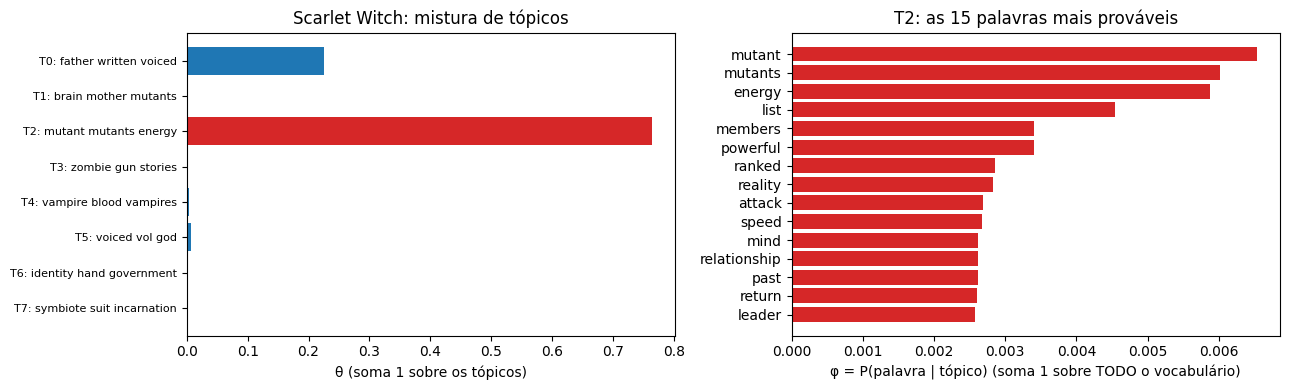

Scarlet Witch: T2 0.76, T0 0.23, T5 0.01, T4 0.00 | soma = 1.000
T2: as 15 palavras somam 0.05 da probabilidade do tópico


In [40]:
# 6.5.3 -- uma página: a mistura de tópicos (nível do documento) e as palavras do tópico mais forte (nível do tópico)
cands_ = ["Doctor Strange", "Blade (character)", "Ghost Rider", "Spider-Man", "Wolverine (character)", "Thor (Marvel Comics)", "Hulk", "Moon Knight", "Scarlet Witch"]
for nm in cands_:
    if nm in name.values():
        ii = IDS.index([n for n in IDS if name[n] == nm][0])
        print(f"{nm:22s}: " + ", ".join(f"T{k} {th_b[ii, k]:.2f}" for k in th_b[ii].argsort()[::-1][:3]))
PAGE = [n for n in IDS if name[n] == "Scarlet Witch"][0]
i = IDS.index(PAGE); mix = th_b[i]; kmax = mix.argmax()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
lbls = [f"T{k}: " + " ".join(w for w, _ in tw_b[k][:3]) for k in range(8)]
axes[0].barh(range(8), mix, color=["C3" if k == kmax else "C0" for k in range(8)])
axes[0].set_yticks(range(8)); axes[0].set_yticklabels(lbls, fontsize=8); axes[0].invert_yaxis()
axes[0].set_xlabel("θ (soma 1 sobre os tópicos)"); axes[0].set_title(f"{name[PAGE]}: mistura de tópicos")
w_, p_ = zip(*top_words(lda_b, vec_b, 15)[kmax])
axes[1].barh(range(15), p_, color="C3"); axes[1].set_yticks(range(15)); axes[1].set_yticklabels(w_); axes[1].invert_yaxis()
axes[1].set_xlabel("φ = P(palavra | tópico) (soma 1 sobre TODO o vocabulário)"); axes[1].set_title(f"T{kmax}: as 15 palavras mais prováveis")
plt.tight_layout(); plt.savefig("figs/6.5_page_mixture_and_topic.png", dpi=150); plt.show()
print(f"{name[PAGE]}: " + ", ".join(f"T{k} {mix[k]:.2f}" for k in mix.argsort()[::-1][:4]), f"| soma = {mix.sum():.3f}")
print(f"T{kmax}: as 15 palavras somam {sum(p_):.2f} da probabilidade do tópico")

**6.5.3 — Uma página: Scarlet Witch.** Mistura (nível do documento, soma 1 sobre os tópicos): **T2 mutantes 0.76**,
T0 boilerplate 0.23, o resto ≈ 0. O tópico mais forte, T2, à direita (nível do tópico, soma 1 sobre **todo** o
vocabulário): as 15 palavras de topo somam só **≈ 5%** da probabilidade do tópico — um tópico é uma distribuição
larga, e as palavras de topo são só a ponta.

Nota da tabela de candidatas: a maior parte das páginas famosas é dominada pelo **T0** (Spider-Man 0.98, Wolverine
0.68, Hulk 0.63) — as páginas mais compridas são as que têm secções enormes de publicação e adaptações. Depois do
filtro de nomes, o que separa uma página do Spider-Man de uma página curta é sobretudo **quanto se escreveu sobre
ela**, não sobre o que ela é.

In [41]:
# 6.5.4 -- estabilidade: mudar a seed (K = 8) e mudar K (4 e 14), mesmo pré-processamento
def phi(l_): return l_.components_ / l_.components_.sum(1, keepdims=True)
v_b = vec_b.get_feature_names_out()
runs = {lbl: LatentDirichletAllocation(n_components=k, random_state=s_, learning_method="batch", max_iter=50).fit(Xb)
        for lbl, k, s_ in [("K8 seed1", 8, 1), ("K8 seed2", 8, 2), ("K4 seed0", 4, 0), ("K14 seed0", 14, 0)]}
best = pd.DataFrame(index=[f"T{k} " + " ".join(w for w, _ in tw_b[k][:2]) for k in range(8)])
for lbl, l_ in runs.items():
    S = cosine_similarity(phi(lda_b), phi(l_))            # semelhança entre distribuições de palavras (base vs nova corrida)
    best[lbl] = [f"{S[k].max():.2f} -> " + " ".join(v_b[t] for t in phi(l_)[S[k].argmax()].argsort()[::-1][:5]) for k in range(8)]
print(best.to_string())
for lbl in ["K4 seed0", "K14 seed0"]:
    print(f"\n{lbl}: todos os tópicos")
    for k, row in enumerate(phi(runs[lbl])):
        print(f"  {k:2d}: " + " ".join(v_b[t] for t in row.argsort()[::-1][:8]))

                                                          K8 seed1                                           K8 seed2                                         K4 seed0                                         K14 seed0
T0 father written       0.87 -> written stories issues film father               0.87 -> best list father voiced film        0.99 -> voiced written father list issues           0.98 -> list written best issues father
T1 brain mother             0.51 -> hand armor energy suit members         0.52 -> mutant mutants energy list members        0.51 -> mutant energy mutants list voiced   0.46 -> mutant mutants list relationship energy
T2 mutant mutants  0.89 -> mutants mutant relationship list return         0.96 -> mutant mutants energy list members        0.98 -> mutant energy mutants list voiced   0.92 -> mutant mutants list relationship energy
T3 zombie gun           0.49 -> written stories issues film father    0.52 -> issues stories written introduced title           0.71

**6.5.4 — Estabilidade** (para cada tópico da corrida base, o tópico mais parecido de cada nova corrida, por
cosseno entre as distribuições de palavras φ):

- **Estáveis:** **T7 simbiontes** (0.95 / 0.80 / 0.91 / 0.97), **T2 mutantes** (0.89 / 0.96 / 0.98 / 0.92) e **T0
  boilerplate** (0.87 / 0.87 / 0.99 / 0.98) aparecem em todas as corridas.
- **Fundem-se:** com **K = 4**, vampiros e simbiontes juntam-se num só tópico (*symbiote suit vampire incarnation
  blood*), e o pulp/horror junta-se a deuses/almas (*vol zombie soul spirit demon*). Com a **seed 1**, os vampiros
  colam-se ao boilerplate (*list voiced vampire ranked blood*).
- **Partem-se / aparecem:** com **K = 14** surge um tópico de **magia** que não existia com 8 (*magic vol soul god
  magical demon*), outro **cósmico** (*energy cosmic space powerful*) e os simbiontes aparecem **duas vezes**
  (um de enredo: *anti suit host attacked bonded*; outro de media: *costume incarnation voiced playable film*).
- **Desaparecem:** o incoerente T1 não tem par acima de 0.52 em nenhuma corrida, e o T6 (combate) só reaparece
  com K = 14 (0.70).

**O que isto diz:** um tópico ajustado é **um resultado de uma corrida**, não um facto sobre o corpus. Só os temas
que sobrevivem a seeds e a K diferentes (aqui: mutantes, simbiontes e o boilerplate) merecem ser tratados como
estrutura; os outros dependem de escolhas arbitrárias.

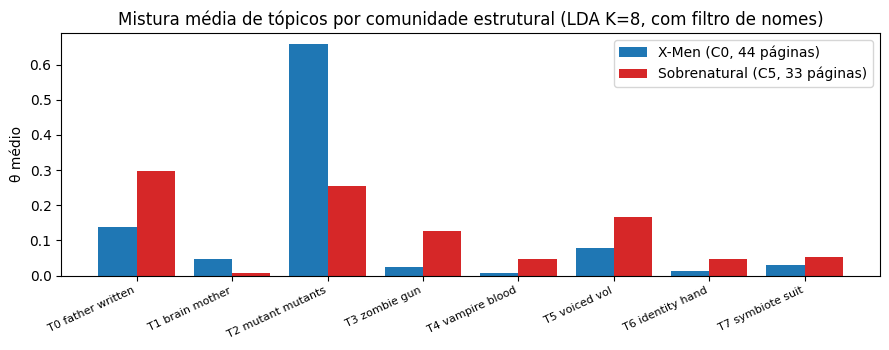

                   X_Men  Sobrenatural
T0 father written   0.14          0.30
T1 brain mother     0.05          0.01
T2 mutant mutants   0.66          0.25
T3 zombie gun       0.02          0.13
T4 vampire blood    0.01          0.05
T5 voiced vol       0.08          0.17
T6 identity hand    0.01          0.05
T7 symbiote suit    0.03          0.05

X-Men com pouco T2: Fabio Medina -> T1 1.00, T2 0.00, T0 0.00
    Fabio Medina is a fictional superhero appearing in American comic books published by Marvel Comics. He previously went by the codename Goldballs, but has changed to Egg following changes in the X-Men during the "Dawn of X" relaunch. The cha

X-Men com pouco T2: Junior Juniper -> T1 1.00, T0 0.00, T5 0.00
    Jonathan "Junior" Juniper is a fictional character appearing in American comic books published by Marvel Comics. Created by Stan Lee and Jack Kirby, his first appearance was in Sgt. Fury and the Howling Commandos vol. 1 #1. He is known to b

X-Men com pouco T2: Blue Bulle

In [42]:
# 6.5.5 -- as duas comunidades do 6.3 diferem no que as páginas falam?
mA = np.array([comm_of[n] == CA for n in IDS]); mB = np.array([comm_of[n] == CB for n in IDS])
lbls_short = [f"T{k} " + " ".join(w for w, _ in tw_b[k][:2]) for k in range(8)]
mean_A, mean_B = th_b[mA].mean(0), th_b[mB].mean(0)
fig, ax = plt.subplots(figsize=(9, 3.6)); x = np.arange(8)
ax.bar(x - 0.2, mean_A, 0.4, label=f"X-Men (C{CA}, {mA.sum()} páginas)"); ax.bar(x + 0.2, mean_B, 0.4, label=f"Sobrenatural (C{CB}, {mB.sum()} páginas)", color="C3")
ax.set_xticks(x); ax.set_xticklabels(lbls_short, rotation=25, ha="right", fontsize=8); ax.set_ylabel("θ médio"); ax.legend()
ax.set_title("Mistura média de tópicos por comunidade estrutural (LDA K=8, com filtro de nomes)")
plt.tight_layout(); plt.savefig("figs/6.5_topics_by_community.png", dpi=150); plt.show()
print(pd.DataFrame(dict(X_Men=mean_A, Sobrenatural=mean_B), index=lbls_short).round(2).to_string())
# a página que não encaixa: dentro das X-Men, a que tem MENOS peso no tópico dominante das X-Men
kA = mean_A.argmax(); kB = mean_B.argmax()
odd = [IDS[i] for i in np.where(mA)[0][np.argsort(th_b[mA, kA])[:3]]]
for n in odd:
    i = IDS.index(n)
    print(f"\nX-Men com pouco T{kA}: {name[n]} -> " + ", ".join(f"T{k} {th_b[i, k]:.2f}" for k in th_b[i].argsort()[::-1][:3]))
    print("   ", marvel_pages[n][:240].replace("\n", " "))

**6.5.5 — As comunidades estruturais falam de coisas diferentes?** Sim, em parte. A figura mostra a mistura média:
as **X-Men** têm **0.66** no tópico mutantes contra 0.25 no sobrenatural; o **sobrenatural** tem mais boilerplate
(0.30 vs 0.14), mais pulp/horror (0.13 vs 0.02), mais *voiced/vol/god* (0.17 vs 0.08) e mais vampiros (0.05 vs
0.01). A estrutura da rede e o texto concordam no grande: as X-Men são o grupo mutante.

**Páginas que não encaixam:** dentro das X-Men, as que têm menos peso no tópico mutante são **Fabio Medina** (100% no
tópico incoerente T1), **Junior Juniper** (T1) e **Blue Bullet** (T3 pulp). Abri-as: *Junior Juniper* é um soldado
dos *Howling Commandos* da 2.ª Guerra (*"first appearance was in Sgt. Fury and the Howling Commandos"*) e
*Blue Bullet* uma homenagem a um herói da Fawcett — **nenhum é X-Man**. Estão na comunidade X-Men pelas
**ligações** (o Louvain junta-os por onde a rede os pôs), não pelo que as páginas dizem; o texto contradiz a rede.
O Fabio Medina é X-Man (*"changes in the X-Men during the 'Dawn of X' relaunch"*), mas a página é curta e o modelo
pô-lo no tópico incoerente — o problema aí é o modelo, não a comunidade.

In [43]:
# 6.5.6 -- teste de sanidade: 20 Newsgroups (onde o LDA é conhecido por funcionar)
try:
    from sklearn.datasets import fetch_20newsgroups
    ng = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
    ng_docs, ng_lab = ng.data, [ng.target_names[t] for t in ng.target]
    print("fonte: sklearn.datasets.fetch_20newsgroups")
except Exception as e:
    # alternativa quando o figshare está bloqueado: o mesmo subset "train" (11 314 posts) num espelho no GitHub,
    # limpo com as MESMAS funções que o sklearn usa para remove=("headers","footers","quotes")
    from sklearn.datasets._twenty_newsgroups import strip_newsgroup_header, strip_newsgroup_footer, strip_newsgroup_quoting
    path = "data/newsgroups_train.json"
    if not os.path.exists(path):
        urllib.request.urlretrieve("https://raw.githubusercontent.com/selva86/datasets/master/newsgroups.json", path)
    raw = json.load(open(path))
    keys = sorted(raw["content"], key=int)
    ng_docs = [strip_newsgroup_quoting(strip_newsgroup_footer(strip_newsgroup_header(raw["content"][k]))) for k in keys]
    ng_lab = [raw["target_names"][k] for k in keys]
    print(f"fonte: espelho GitHub (fetch_20newsgroups falhou: {type(e).__name__})")
print(f"{len(ng_docs):,} posts, {len(set(ng_lab))} grupos")

vec_ng = CountVectorizer(stop_words="english", min_df=5, max_df=0.5, token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")
X_ng = vec_ng.fit_transform(ng_docs)
lda_ng = LatentDirichletAllocation(n_components=10, random_state=0, learning_method="online", batch_size=512, max_iter=20)
th_ng = lda_ng.fit_transform(X_ng)
v_ng = vec_ng.get_feature_names_out()
lab = np.array(ng_lab)
for k in range(10):
    dom = th_ng.argmax(1) == k
    grp = Counter(lab[dom]).most_common(3); n_ = dom.sum()
    print(f"T{k} ({n_:5d} posts) " + " ".join(v_ng[i] for i in lda_ng.components_[k].argsort()[::-1][:9]))
    print("      grupos: " + ", ".join(f"{g} {c / max(n_, 1):.0%}" for g, c in grp))

fonte: sklearn.datasets.fetch_20newsgroups
11,314 posts, 20 grupos
T0 ( 1909 posts) time new years president use like just mr year
      grupos: sci.med 17%, sci.space 16%, rec.motorcycles 15%
T1 ( 3474 posts) people don god just think know like say does
      grupos: soc.religion.christian 16%, alt.atheism 12%, talk.politics.guns 11%
T2 (   10 posts) ax max pl giz bhj wm bxn gk sl
      grupos: comp.os.ms-windows.misc 100%
T3 (  884 posts) file program edu available space use ftp image window
      grupos: comp.windows.x 42%, comp.graphics 25%, sci.space 11%
T4 (  492 posts) key edu com encryption information chip public government keys
      grupos: sci.crypt 43%, rec.autos 16%, misc.forsale 7%
T5 (  595 posts) db good new sale used books box ground condition
      grupos: misc.forsale 37%, sci.electronics 31%, rec.motorcycles 9%
T6 (  374 posts) israel armenian people jews armenians war turkish israeli said
      grupos: talk.politics.mideast 75%, alt.atheism 4%, talk.politics.misc 

**6.5.6 — 20 Newsgroups (10 tópicos, mesmo código).** *(Neste ambiente o figshare do scikit-learn estava
bloqueado; a célula usou um espelho do mesmo subset "train", 11 314 posts, limpo com as mesmas funções do
`remove=(…)`. No portátil corre o `fetch_20newsgroups` normal.)*

- **Correspondem a um grupo:** **T6** *israel armenian jews turkish* → **talk.politics.mideast 75%**; **T7** *team
  game season hockey league players* → **rec.sport.hockey 50% + rec.sport.baseball 45%** (um tópico "desporto", dois
  grupos); **T4** *key encryption chip government keys* → **sci.crypt 43%**; **T3** *file program ftp image window* →
  comp.windows.x 42% + comp.graphics 25%; **T5** *sale used condition box* → misc.forsale 37%; **T8** *windows drive
  card* → hardware de PC/Mac.
- **Recuso-me a nomear:** **T2** (*ax max pl giz bhj …*, 10 posts) e **T9** (*cx ah chz lk …*, 22 posts) — são
  ficheiros binários codificados colados nos posts, não linguagem; **T0** (*time new years president use like*) e
  **T1** (*people don god think know*) são tópicos-esponja de palavras genéricas que misturam muitos grupos (T1 é
  meio religião, meio política).

**Onde está a dificuldade com Marvel: no corpus, não no método.** O mesmo código encontra os grupos de discussão
porque esses grupos têm **vocabulários de tema separados** e milhares de documentos curtos, cada um sobre uma coisa.
O corpus Marvel tem 303 documentos **longos**, todos do **mesmo género** (biografia de personagem + publicação +
adaptações), onde o que mais distingue as páginas são **nomes** — que o LDA transforma em tópicos-personagem — e,
tirados os nomes, a **estrutura** das páginas (o boilerplate de media). Os temas existem (mutantes, simbiontes,
vampiros), mas são minoritários dentro de cada página.

---
## 📘 Exemplo da página — Secção 4 · Now let's think about words

**Uma linha da matriz palavra-contexto é um `Counter`** das palavras dentro da janela, somado sobre todas as
ocorrências da palavra alvo. Com janela 1, todos os contextos de *tezgüino* aparecem também à volta de *wine* ou
de *bourbon* — a versão em matriz do palpite que se faz ao ler as quatro frases.

In [44]:
import re
from collections import Counter

sentences = [
    "A bottle of tezgüino sits on the table.", "Everybody likes tezgüino.",
    "Tezgüino makes you drunk.", "We make tezgüino from corn.",
    "A bottle of wine sits on the table.", "Everybody likes wine.",
    "Wine makes you drunk.", "We make bourbon from corn.", "Bourbon makes you drunk.",
]
tokenized = [re.findall(r"\w+", s.lower()) for s in sentences]

def context_row(target, window):
    row = Counter()
    for tokens in tokenized:
        for i, word in enumerate(tokens):
            if word == target:
                row.update(tokens[max(0, i - window):i] + tokens[i + 1:i + 1 + window])
    return row

for w in ["tezgüino", "wine", "bourbon"]:
    print(w, dict(context_row(w, 1)))
# tezgüino {'of': 1, 'sits': 1, 'likes': 1, 'makes': 1, 'make': 1, 'from': 1}
# wine {'of': 1, 'sits': 1, 'likes': 1, 'makes': 1}
# bourbon {'make': 1, 'from': 1, 'makes': 1}

tezgüino {'of': 1, 'sits': 1, 'likes': 1, 'makes': 1, 'make': 1, 'from': 1}
wine {'of': 1, 'sits': 1, 'likes': 1, 'makes': 1}
bourbon {'make': 1, 'from': 1, 'makes': 1}


A sugestão da página: *"Try a window of 2 and watch bottle, you and corn arrive; the overlap still holds."*

In [45]:
for w in ["tezgüino", "wine", "bourbon"]:
    print(w, dict(context_row(w, 2)))

tezgüino {'bottle': 1, 'of': 1, 'sits': 1, 'on': 1, 'everybody': 1, 'likes': 1, 'makes': 1, 'you': 1, 'we': 1, 'make': 1, 'from': 1, 'corn': 1}
wine {'bottle': 1, 'of': 1, 'sits': 1, 'on': 1, 'everybody': 1, 'likes': 1, 'makes': 1, 'you': 1}
bourbon {'we': 1, 'make': 1, 'from': 1, 'corn': 1, 'makes': 1, 'you': 1}


## 📘 Exemplo da página — Secção 5 · Raw co-occurrence is not enough

**A matriz do explorable em NumPy.** As três probabilidades têm uma linha cada: célula ÷ total = $P(w,c)$,
totais das linhas = $P(w)$, totais das colunas = $P(c)$. Com contagens, *dog* e *finance* ficam a cosseno
**0.72**, quase tudo por causa do *the*; com PPMI ficam a **0**.

In [46]:
import numpy as np

words = ["dog", "puppy", "cat", "bank", "finance", "democracy", "election"]
contexts = ["the", "bark", "leash", "pet", "vote", "money", "river"]
C = np.array([
    [30, 12,  9, 10,  0,  0,  0],
    [25,  8, 10, 12,  0,  0,  0],
    [28,  0,  1, 13,  0,  0,  0],
    [30,  0,  0,  0,  2, 15, 13],
    [22,  0,  0,  0,  3, 14,  0],
    [24,  0,  0,  0, 16,  2,  0],
    [20,  0,  0,  0, 15,  1,  0],
])

P = C / C.sum()                        # P(w, c): each cell over the grand total
Pw = P.sum(axis=1, keepdims=True)      # P(w): row totals
Pc = P.sum(axis=0, keepdims=True)      # P(c): column totals
with np.errstate(divide="ignore"):     # log2(0) = -inf for the empty cells
    pmi = np.log2(P / (Pw * Pc))
ppmi = np.maximum(pmi, 0)

def cos(M, a, b):
    va, vb = M[words.index(a)], M[words.index(b)]
    return va @ vb / (np.linalg.norm(va) * np.linalg.norm(vb))

print(round(cos(C, "dog", "finance"), 2), round(cos(ppmi, "dog", "finance"), 2))
# 0.72 0.0

0.72 0.0


A frase seguinte da página: *"dog and puppy stay close (0.96)"*. Verificação, e a tabela PPMI inteira para ver
que coluna desapareceu (o *the* fica a 0 em quase todas as linhas):

In [47]:
print("dog–puppy:", round(cos(ppmi, "dog", "puppy"), 2))
import pandas as pd
print(pd.DataFrame(ppmi, index=words, columns=contexts).round(2).to_string())

dog–puppy: 0.96
            the  bark  leash   pet  vote  money  river
dog        0.00  1.72   1.31  0.65  0.00   0.00   0.00
puppy      0.00  1.28   1.61  1.06  0.00   0.00   0.00
cat        0.32  0.00   0.00  1.57  0.00   0.00   0.00
bank       0.00  0.00   0.00  0.00  0.00   1.39   2.48
finance    0.08  0.00   0.00  0.00  0.00   1.91   0.00
democracy  0.10  0.00   0.00  0.00  1.83   0.00   0.00
election   0.06  0.00   0.00  0.00  1.96   0.00   0.00


## Exercício 6.6 — Word context and PPMI, by hand (🧠 learn)

> Do the small calculation yourself before you ask a library to build a matrix with thousands of context dimensions.
>
> 1. Take the sentence *the puppy chased the ball through the park*. For the target word *chased*, write down the context words for a window of 1 and then for a window of 2. What information changes when the window becomes wider?
> 2. Draw a tiny word-context matrix with two target words and three context words. Choose counts so that one context is common for both target words and one context is strongly associated with only one target.
> 3. From your table, compute $P(w,c)$, $P(w)$ and $P(c)$ for one cell, then calculate its PMI and PPMI. Say what the sign of the PMI told you before you clipped it at zero.
> 4. Explain why replacing raw co-occurrence counts with PPMI can change which word is the nearest neighbor under cosine similarity.

### 6.6.1 — Janelas

Frase: *the(1) puppy(2) **chased**(3) the(4) ball(5) through(6) the(7) park(8)*.

- **Janela ±1** (uma palavra de cada lado): **puppy, the**.
- **Janela ±2** (duas de cada lado): **the, puppy, the, ball**.

**O que muda:** com ±1 só se vê a vizinhança sintática imediata — quem faz a ação (*puppy*) e o artigo do objeto.
Com ±2 entra o **objeto da perseguição** (*ball*) e mais um *the*: mais informação sobre o tipo de evento (o que se
persegue), mas também mais palavras de função. Janelas largas puxam para associações **temáticas**, estreitas
para **sintáticas** (o 6.7.5 mostra isto no corpus).

### 6.6.2 — A minha matriz (2 alvos × 3 contextos)

| | the | bark | money | total (linha) |
|---|:-:|:-:|:-:|:-:|
| **dog** | 4 | 3 | 1 | 8 |
| **bank** | 4 | 0 | 4 | 8 |
| **total (coluna)** | 8 | 3 | 5 | **16** |

*the* é **comum aos dois** (4 e 4); *bark* está **fortemente associado só a dog** (3 e 0); *money* é sobretudo de *bank*.

### 6.6.3 — Uma célula: (dog, bark)

**Passo 1 — probabilidades a partir das contagens** (célula / total; margens / total):
$$
P(\textit{dog},\textit{bark}) = \frac{3}{16} = 0.1875
$$
$$
P(\textit{dog}) = \frac{8}{16} = 0.5, \qquad P(\textit{bark}) = \frac{3}{16} = 0.1875
$$
**Passo 2 — o que a independência preveria:**
$$
P(\textit{dog})\,P(\textit{bark}) = 0.5 \cdot 0.1875 = 0.09375
$$
**Passo 3 — PMI:**
$$
\mathrm{PMI}(\textit{dog},\textit{bark}) = \log_2\frac{0.1875}{0.09375} = \log_2 2 = 1
$$
$$
\mathrm{PPMI} = \max(1, 0) = 1
$$
**O sinal:** positivo → *dog* e *bark* aparecem juntos **2× mais** do que se fossem independentes: associação real.

**Contraste com as outras duas células de dog** (mesmo método):
$$
\mathrm{PMI}(\textit{dog},\textit{the}) = \log_2\frac{4/16}{0.5\cdot 8/16} = \log_2\frac{0.25}{0.25} = \log_2 1 = 0 \quad\Rightarrow\quad \mathrm{PPMI} = 0
$$
$$
\mathrm{PMI}(\textit{dog},\textit{money}) = \log_2\frac{1/16}{0.5\cdot 5/16} = \log_2\frac{0.0625}{0.15625} = \log_2 0.4 = -1.32 \quad\Rightarrow\quad \mathrm{PPMI} = 0
$$
O *the* tem PMI **0**: aparece com *dog* exatamente tanto quanto se esperava — não diz nada. O *money* tem PMI
**negativo**: aparece com *dog* **menos** do que o acaso preveria (0.4× o esperado) — uma "anti-associação", que o
PPMI corta a zero porque estimativas negativas com poucas contagens são pouco fiáveis.

### 6.6.4 — Porque é que o PPMI pode mudar o vizinho mais próximo

Com contagens brutas, os contextos **frequentes e pouco informativos** (*the*, *of*) dominam o comprimento de todas
as linhas, e o cosseno — que compara direções — fica a medir sobretudo "quanto *the* tem cada palavra". Duas palavras
sem nada em comum a não ser *the* ficam próximas (na página: dog–finance = **0.72**). O PPMI põe esses contextos
perto de 0 (PMI ≈ 0 para um contexto que aparece com toda a gente) e dá peso aos contextos **inesperadamente**
associados; o cosseno passa a comparar as associações específicas, e o vizinho pode mudar.

Exemplo meu (verificado abaixo): contextos *the, fight, cape, laugh*; *hero* = [20, 4, 4, 0], *villain* = [20, 4, 0, 4],
*sidekick* = [2, 0, 3, 0]. Com contagens, cos(hero, villain) = **0.963** e cos(hero, sidekick) = **0.694** → o vizinho
de *hero* é *villain* (por causa dos 20 *the*). Com PPMI, cos(hero, villain) = **0.046** e cos(hero, sidekick) =
**0.920** → o vizinho passa a ser *sidekick*, por causa do contexto específico partilhado, *cape*.

In [48]:
# Verificação do 6.6
sent = "the puppy chased the ball through the park".split()
k = sent.index("chased")
for win in (1, 2):
    print(f"janela ±{win}: contextos de 'chased' =", sent[max(0, k - win):k] + sent[k + 1:k + 1 + win])

Ctiny = pd.DataFrame([[4, 3, 1], [4, 0, 4]], index=["dog", "bank"], columns=["the", "bark", "money"])
Pt = Ctiny / Ctiny.values.sum()
Pw_, Pc_ = Pt.sum(axis=1), Pt.sum(axis=0)
PMI_t = np.log2(Pt.div(Pw_, axis=0).div(Pc_, axis=1).replace(0, np.nan))
print("\nP(w,c):\n", Pt.round(4).to_string(), "\nP(w):", Pw_.round(3).to_dict(), " P(c):", Pc_.round(4).to_dict())
print("\nPMI:\n", PMI_t.round(3).to_string(), "\n\nPPMI:\n", PMI_t.clip(lower=0).fillna(0).round(3).to_string())

# o exemplo da página: dog / puppy / finance, contagens vs PPMI
words = ["dog", "puppy", "cat", "bank", "finance", "democracy", "election"]
Cx = np.array([[30, 12, 9, 10, 0, 0, 0], [25, 8, 10, 12, 0, 0, 0], [28, 0, 1, 13, 0, 0, 0], [30, 0, 0, 0, 2, 15, 13],
               [22, 0, 0, 0, 3, 14, 0], [24, 0, 0, 0, 16, 2, 0], [20, 0, 0, 0, 15, 1, 0]])
Px = Cx / Cx.sum(); Pwx = Px.sum(1, keepdims=True); Pcx = Px.sum(0, keepdims=True)
with np.errstate(divide="ignore"): ppmi_x = np.maximum(np.log2(Px / (Pwx * Pcx)), 0)
def cosw(M, a, b): va, vb = M[words.index(a)], M[words.index(b)]; return va @ vb / (np.linalg.norm(va) * np.linalg.norm(vb))
for a, b in [("dog", "finance"), ("dog", "puppy"), ("bank", "finance")]:
    print(f"cos({a},{b}): contagens {cosw(Cx, a, b):.2f} -> PPMI {cosw(ppmi_x, a, b):.2f}")
# 6.6.4 -- um exemplo meu em que o vizinho mais próximo MUDA
C4 = pd.DataFrame([[20, 4, 4, 0], [20, 4, 0, 4], [2, 0, 3, 0]], index=["hero", "villain", "sidekick"],
                  columns=["the", "fight", "cape", "laugh"])
P4 = C4 / C4.values.sum()
PMI4 = np.log2(P4.div(P4.sum(axis=1), axis=0).div(P4.sum(axis=0), axis=1).replace(0, np.nan))
PPMI4 = PMI4.clip(lower=0).fillna(0)
print("\nPMI:\n", PMI4.round(3).to_string())
for M_, lbl in [(C4.values.astype(float), "contagens"), (PPMI4.values, "PPMI")]:
    cs = cosine_similarity(M_)
    print(f"{lbl:9s}: cos(hero,villain) = {cs[0, 1]:.3f}   cos(hero,sidekick) = {cs[0, 2]:.3f}   -> vizinho de hero: {['villain', 'sidekick'][int(cs[0, 2] > cs[0, 1])]}")


janela ±1: contextos de 'chased' = ['puppy', 'the']
janela ±2: contextos de 'chased' = ['the', 'puppy', 'the', 'ball']

P(w,c):
        the    bark   money
dog   0.25  0.1875  0.0625
bank  0.25  0.0000  0.2500 
P(w): {'dog': 0.5, 'bank': 0.5}  P(c): {'the': 0.5, 'bark': 0.1875, 'money': 0.3125}

PMI:
       the  bark  money
dog   0.0   1.0 -1.322
bank  0.0   NaN  0.678 

PPMI:
       the  bark  money
dog   0.0   1.0  0.000
bank  0.0   0.0  0.678
cos(dog,finance): contagens 0.72 -> PPMI 0.00
cos(dog,puppy): contagens 0.99 -> PPMI 0.96
cos(bank,finance): contagens 0.93 -> PPMI 0.49

PMI:
             the  fight   cape  laugh
hero      0.053  0.123  0.316    NaN
villain   0.053  0.123    NaN  1.123
sidekick -0.784    NaN  2.386    NaN
contagens: cos(hero,villain) = 0.963   cos(hero,sidekick) = 0.694   -> vizinho de hero: villain
PPMI     : cos(hero,villain) = 0.046   cos(hero,sidekick) = 0.920   -> vizinho de hero: sidekick


A verificação confirma as janelas, a tabela de PMI (dog–bark **1.0**, dog–the **0.0**, dog–money **−1.322**,
bank–money 0.678), o exemplo da página (dog–finance 0.72 → **0.00**, dog–puppy 0.99 → 0.96) e a troca de vizinho
(hero: villain 0.963 → sidekick 0.920).

## Exercício 6.7 — PPMI neighbors on Marvel, as code (🔬 tool)

> Now make the context matrix real.
>
> 1. Build a word-context matrix from the Marvel corpus using one explicit context-window size. Record the window size and the preprocessing choices that determine which words can become rows and columns.
> 2. Compute PPMI. Pick one cell and verify it independently from the underlying counts before you trust the whole transformed matrix.
> 3. Use cosine similarity to find neighbors for five words. For each word, compare the neighbors from the raw-count matrix with the neighbors from the PPMI matrix.
> 4. Inspect the week 5 concordance lines for at least one convincing neighbor and one strange neighbor. Explain what the context window captured in each case.
> 5. Change the context-window size and rerun one word. Did the neighbors become more syntactic, more topical, or simply noisier? Use the raw text to support your answer.

In [49]:
# 6.7.1 -- matriz palavra-contexto do corpus Marvel
# ESCOLHAS: tokens = só letras, minúsculas (regex [a-z]+ após lowercase; "X-Men" -> "x", "men");
#           as janelas não atravessam páginas; janela SIMÉTRICA de ±2 tokens; stopwords mantidas;
#           linhas E colunas = as palavras com >= 20 ocorrências no corpus (as outras ocupam posições na janela
#           mas não são contadas). Contagem = nº de vezes que a coluna aparece na janela da linha.
page_tokens = [re.findall(r"[a-z]+", t.lower()) for t in texts]
wc = Counter(w for p in page_tokens for w in p)
MINC = 20
vocab_w = sorted(w for w, c in wc.items() if c >= MINC); widx = {w: i for i, w in enumerate(vocab_w)}
print(f"{sum(wc.values()):,} tokens, {len(wc):,} types; vocabulário da matriz (>= {MINC}): {len(vocab_w):,}")

def cooc(window):
    rows_, cols_ = [], []
    for p in page_tokens:
        ids = np.array([widx.get(w, -1) for w in p])
        for d in range(1, window + 1):
            a, b = ids[:-d], ids[d:]; ok = (a >= 0) & (b >= 0)
            rows_ += [a[ok], b[ok]]; cols_ += [b[ok], a[ok]]          # simétrica: os dois sentidos
    r, c = np.concatenate(rows_), np.concatenate(cols_)
    return sparse.coo_matrix((np.ones(len(r)), (r, c)), shape=(len(vocab_w),) * 2).tocsr()

def ppmi(C):
    C = C.tocoo(); total = C.sum()
    rs = np.asarray(C.sum(1)).ravel(); cs = np.asarray(C.sum(0)).ravel()
    pmi = np.log2(C.data * total / (rs[C.row] * cs[C.col]))
    keep = pmi > 0
    return sparse.csr_matrix((pmi[keep], (C.row[keep], C.col[keep])), shape=C.shape)

C2 = cooc(2); M2 = ppmi(C2)
print(f"janela ±2: {C2.nnz:,} células não nulas ({C2.nnz / C2.shape[0] ** 2:.2%}), {C2.sum():,.0f} pares contados; "
      f"PPMI > 0 em {M2.nnz:,} células ({M2.nnz / C2.nnz:.0%} das não nulas)")

736,659 tokens, 25,254 types; vocabulário da matriz (>= 20): 3,725
janela ±2: 563,736 células não nulas (4.06%), 2,332,634 pares contados; PPMI > 0 em 471,553 células (84% das não nulas)


**6.7.1 — Escolhas:** tokens = sequências de letras após lowercase (`[a-z]+`, *X-Men* → *x* + *men*, *Thor's* → *thor* + *s*);
janela **simétrica ±2**; as janelas **não atravessam páginas**; stopwords **mantidas**; linhas e colunas = as
**3 725** palavras com ≥ 20 ocorrências (as outras ocupam lugar na janela mas não se contam). Matriz 3 725 × 3 725
com 4.06% de células não nulas e 2 332 634 pares contados; o PPMI é positivo em 84% das células não nulas.

In [50]:
# 6.7.2 -- verificar UMA célula do PPMI à mão, a partir das contagens
w, c = "hammer", "thor"
i, j = widx[w], widx[c]
n_wc = C2[i, j]; n_w = C2[i].sum(); n_c = C2[:, j].sum(); n_tot = C2.sum()
P_wc, P_w, P_c = n_wc / n_tot, n_w / n_tot, n_c / n_tot
pmi_hand = math.log2(P_wc / (P_w * P_c))
print(f"count({w},{c}) = {n_wc:.0f}   linha '{w}' = {n_w:,.0f}   coluna '{c}' = {n_c:,.0f}   total = {n_tot:,.0f}")
print(f"P(w,c) = {P_wc:.3e}   P(w) = {P_w:.3e}   P(c) = {P_c:.3e}")
print(f"PMI = log2({P_wc:.3e} / ({P_w:.3e} · {P_c:.3e})) = log2({P_wc / (P_w * P_c):.1f}) = {pmi_hand:.3f}  | matriz: {M2[i, j]:.3f}")
# e um contexto comum: 'the' perto de 'hammer'
j2 = widx["the"]; r_ = C2[i, j2] * n_tot / (n_w * C2[:, j2].sum())
print(f"count(hammer, the) = {C2[i, j2]:.0f} -> PMI = log2({r_:.2f}) = {math.log2(r_):.2f} -> PPMI = {M2[i, j2]:.2f}")
# confirmar a contagem no texto: quantas vezes "thor" está a <= 2 tokens de "hammer"?
n_text = sum(1 for p in page_tokens for k, t in enumerate(p) if t == "hammer" for d in (-2, -1, 1, 2)
             if 0 <= k + d < len(p) and p[k + d] == "thor")
print(f"contado diretamente nas listas de tokens: {n_text}")

count(hammer,thor) = 8   linha 'hammer' = 316   coluna 'thor' = 1,225   total = 2,332,634
P(w,c) = 3.430e-06   P(w) = 1.355e-04   P(c) = 5.252e-04
PMI = log2(3.430e-06 / (1.355e-04 · 5.252e-04)) = log2(48.2) = 5.591  | matriz: 5.591
count(hammer, the) = 20 -> PMI = log2(0.92) = -0.12 -> PPMI = 0.00
contado diretamente nas listas de tokens: 8


**6.7.2 — Uma célula verificada: (hammer, thor).**
$$
P(w,c) = \frac{8}{2\,332\,634} = 3.43\times10^{-6}, \qquad P(w) = \frac{316}{2\,332\,634} = 1.355\times10^{-4}, \qquad P(c) = \frac{1\,225}{2\,332\,634} = 5.25\times10^{-4}
$$
$$
\mathrm{PMI} = \log_2\frac{3.43\times10^{-6}}{1.355\times10^{-4}\cdot5.25\times10^{-4}} = \log_2 48.2 = 5.59
$$
Igual à matriz (**5.591**), e a contagem 8 confirma-se diretamente nas listas de tokens. Contraste: *hammer–the* tem
20 co-ocorrências mas PMI = log₂ 0.92 = −0.12 → PPMI **0** — o contexto mais frequente de *hammer* desaparece.

In [51]:
# 6.7.3 -- vizinhos por cosseno: contagens brutas vs PPMI
Cn2, Mn2 = normalize(C2), normalize(M2)
def nn(Mn, w, k=8):
    s = (Mn @ Mn[widx[w]].T).toarray().ravel(); s[widx[w]] = -1
    return [vocab_w[j] for j in s.argsort()[::-1][:k]]
WORDS = ["hammer", "mutant", "symbiote", "wife", "telepathic"]
tab = pd.DataFrame({w: [" ".join(nn(Cn2, w)), " ".join(nn(Mn2, w))] for w in WORDS}, index=["contagens", "PPMI"]).T
print(tab.to_string())

                                                                       contagens                                                                   PPMI
hammer                 storm death magneto wolverine suit consciousness head run                mjolnir odin receives worthy lift industries wield bill
mutant                supervillain great gang champion group victim couple child                            mutants powers her his a who superhuman and
symbiote                     latter of kingpin inheritors raft twins sentry crew                          venom brock bonded him flash carnage andi she
wife                        sister body minions legs own teammates parents uncle            mother friend girlfriend weying father husband daughter and
telepathic  telekinetic psychic powers magical physical mental psionic telepathy  psychic telepathy telekinetic magical psionic her channel telekinesis


**6.7.3 — Contagens vs PPMI** (8 vizinhos por cosseno):

- **hammer** — contagens: *storm, death, magneto, wolverine, suit, consciousness* (palavras com o mesmo perfil de
  *the/s/and* à volta, sem relação com martelos); PPMI: ***mjolnir, odin, worthy, lift, wield, stormbreaker, bill***
  (o martelo de Thor, quem é "digno" de o levantar, Beta Ray Bill) — mais *industries, justin* (ver 6.7.4).
- **mutant** — contagens: *supervillain, great, gang, champion, group*; PPMI: *mutants, powers, superhuman, abilities*
  — mas também ***her, his, a, who, and*** (um defeito conhecido: as linhas PPMI de palavras de função são muito
  densas e sobrepõem-se a tudo).
- **symbiote** — contagens: *latter, of, kingpin, raft, twins*; PPMI: ***venom, brock, bonded, carnage, flash, andi***
  (Flash Thompson e Andi Benton foram hospedeiros). Excelente.
- **wife** — contagens: *sister, body, minions, legs, own*; PPMI: ***mother, friend, girlfriend, father, husband,
  daughter, married*** (+ *weying*: Anne Weying, a She-Venom, ex-mulher de Eddie Brock — um apelido que aparece sempre ao lado de *wife*).
- **telepathic** — as duas listas são boas (*telekinetic, psychic, psionic, telepathy, telekinesis*): é uma palavra
  com contextos muito característicos (*telepathic powers/abilities*).

Padrão: com contagens, os vizinhos são palavras com o mesmo **perfil de palavras de função** à volta; o PPMI tira
esse perfil e deixa os contextos específicos — passa de quase lixo a listas com sentido em 4 das 5 palavras.

In [52]:
# 6.7.4 -- voltar ao texto: linhas de concordância (como na semana 5) para um vizinho convincente e um estranho
corpus_text = Text([w for p in page_tokens for w in p])
print("vizinho convincente — 'hammer' ~ 'mjolnir':"); corpus_text.concordance("mjolnir", width=100, lines=4)
print("\nvizinho estranho — 'hammer' ~ 'industries' (e 'justin'):"); corpus_text.concordance("industries", width=100, lines=6)
cc = Counter()
for p in page_tokens:
    for k, t in enumerate(p):
        if t == "hammer":
            for d in (-2, -1, 1, 2):
                if 0 <= k + d < len(p): cc[p[k + d]] += 1
print("\ncontextos mais comuns de 'hammer' (janela ±2):", cc.most_common(14))
hm, ind = Mn2[widx["hammer"]].toarray().ravel(), Mn2[widx["industries"]].toarray().ravel()
sh = hm * ind
print(f"cos PPMI(hammer, industries) = {sh.sum():.3f}; contextos que o fazem: " + ", ".join(f"{vocab_w[k]} {sh[k] / sh.sum():.0%}" for k in sh.argsort()[::-1][:6]))
raw_all = "\n".join(texts)
print("no texto em bruto: 'Hammer Industries'", len(re.findall(r"Hammer Industries", raw_all)), "| 'Justin Hammer'", len(re.findall(r"Justin Hammer", raw_all)),
      "| 'hammer' minúsculo", len(re.findall(r"\bhammer\b", raw_all)), "| 'Hammer' maiúsculo", len(re.findall(r"\bHammer\b", raw_all)))

vizinho convincente — 'hammer' ~ 'mjolnir':
Displaying 4 of 41 matches:
ring they are all evil uses his mystic hammer mjolnir to time travel several hours into the past to
oduced as being worthy to wield thor s hammer mjolnir after an initial rivalry with thor for posses
 things about thor was the enchantment around mjolnir and the original inscription on it so i thoug
of the mystical enchantments of thor s hammer mjolnir comes into effect which means that thor will 

vizinho estranho — 'hammer' ~ 'industries' (e 'justin'):
Displaying 6 of 38 matches:
n angel s board of directors for worthington industries anole later graduates to official x men stat
ism in later years felicia infiltrated stark industries to construct her own iron cat armor joined o
 technopathy through the use of future stark industries technology as of the end of the avengers x s
 negative he has the duo bring him to parker industries in shanghai although peter is able to escape
njected with an antidote developed by 

**6.7.4 — Concordâncias.**

- **Convincente — *hammer* ~ *mjolnir*:** as linhas dizem *"uses his mystic hammer mjolnir"*, *"worthy to wield thor
  s hammer mjolnir"*. A janela ±2 apanhou a **aposição**: *mjolnir* aparece literalmente ao lado de *hammer* (10 das
  co-ocorrências) e os dois partilham *thor, s, wield, worthy*. Vizinhos por uma razão certa.
- **Estranho — *hammer* ~ *industries* (e *justin*, *sasha*):** as concordâncias de *industries* são *stark
  industries*, *parker industries*, *worthington industries* — empresas. A ligação a *hammer* vem de **Justin Hammer**
  e **Sasha Hammer** (8 + 6 co-ocorrências) e da **Hammer Industries**: no texto em bruto há 52 *Hammer* com maiúscula
  contra 40 *hammer* minúsculo. O lowercase fundiu o **apelido de um vilão** com o **objeto**, e a linha *hammer*
  herdou contextos de empresas (*running, company, behalf, detroit*), que são os que tornam o cosseno com *industries*
  positivo (0.127). A janela fez o seu trabalho; o pré-processamento é que misturou duas palavras numa — é a
  polissemia "fabricada" pelo lowercase, o mesmo problema de *Storm* na semana 5.

In [53]:
# 6.7.5 -- mudar a janela: ±2 vs ±10 para a mesma palavra
C10 = cooc(10); M10 = ppmi(C10); Mn10 = normalize(M10)
C1 = cooc(1); M1 = ppmi(C1); Mn1 = normalize(M1)
for w in ["hammer", "wife", "killed"]:
    print(f"{w:8s} ±1 : {' '.join(nn(Mn1, w, 10))}")
    print(f"{'':8s} ±2 : {' '.join(nn(Mn2, w, 10))}")
    print(f"{'':8s} ±10: {' '.join(nn(Mn10, w, 10))}\n")

hammer   ±1 : wield behalf missing receives gray bill blasts transforms honor tale
         ±2 : mjolnir odin receives worthy lift industries wield bill stormbreaker justin
         ±10: mjolnir thor stormbreaker bill falls justin detroit against weapon he

wife     ±1 : girlfriend mother loves daughter husband friend stein boyfriend currently lover
         ±2 : mother friend girlfriend weying father husband daughter and married peter
         ±10: eventually his father ex mother after son before children and

killed   ±1 : killing transported died defeated cured murdered freed captured kills arrested
         ±2 : kills who killing died is but murdered attacked and after
         ±10: after death who when is battle but them kill then



**6.7.5 — Mudar a janela (±1, ±2, ±10).**

- ***killed*** — **±1:** *killing, died, defeated, murdered, freed, captured, kills, arrested* — **sintático**:
  verbos no particípio que ocupam o mesmo lugar (*was ___ by*). **±10:** *after, death, who, when, battle, them, kill*
  — **temático** (o campo da morte e do combate) e com mais palavras de função.
- ***wife*** — **±1:** *girlfriend, mother, daughter, husband, boyfriend, lover* (substitutos diretos: *his ___*);
  **±10:** *eventually, his, father, ex, after, son, children* — mais temático (família, narrativa) e **mais ruidoso**.
- ***hammer*** — **±1:** *wield, behalf, receives, gray, bill* (já com ruído); **±2:** o melhor equilíbrio;
  **±10:** *mjolnir, thor, stormbreaker, bill, falls, justin, detroit, against, weapon* — temático (o mundo de Thor),
  com o vilão Justin Hammer e *detroit* (o **Detroit Steel**, a armadura que a Hammer Industries vende) misturados.

Conclusão, apoiada no texto: janelas pequenas dão vizinhos **sintáticos/substituíveis** (palavras que podem
trocar de lugar com a alvo), janelas grandes dão vizinhos **temáticos** e, com só 700 mil tokens, **mais ruído**
(palavras de função e coincidências narrativas entram na janela).

---
## 📘 Exemplos da página — Secção 6 · Learn dense word embeddings

**Bloco 1 — Word2Vec no corpus Marvel com o `gensim`.** As frases vêm de um separador simples (corta depois de
`.`, `!`, `?`) e do `simple_preprocess` (minúsculas, sem pontuação). `sg=1` é Skip-gram (0 seria CBOW);
`workers=1` torna a corrida reprodutível. A página obteve primeiro *mjolnir* e *odinson* (certos) e depois
*truck, hide, torn, inevitably* (ruído), e avisa que a lista pode mudar com a versão do gensim.

In [56]:
%conda install -y -c conda-forge gensim

Solving environment: done

## Package Plan ##

  environment location: c:\Users\carlo\miniforge3\envs\dtu02452

  added / updated specs:
    - gensim


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    gensim-4.4.0               |  py312h885b0b7_0        39.2 MB
    smart_open-8.0.3           |     pyh5ded981_0          60 KB  conda-forge
    ------------------------------------------------------------
                                           Total:        39.3 MB

The following NEW packages will be INSTALLED:

  gensim             pkgs/main/win-64::gensim-4.4.0-py312h885b0b7_0 
  smart_open         conda-forge/noarch::smart_open-8.0.3-pyh5ded981_0 



gensim-4.4.0         | 39.2 MB   |            |   0% 

smart_open-8.0.3     | 60 KB     |            |   0% 
gensim-4.4.0         | 39.2 MB   |            |   0% 

smart_open-8.0.3     | 60 KB     | ##6        |  27% 

smart_open-8.0.3    



==> WARNING: A newer version of conda exists. <==
  current version: 24.11.3
  latest version: 26.9.3

Please update conda by running

    $ conda update -n base -c defaults conda

Or to minimize the number of packages updated during conda update use

     conda install conda=26.9.3




In [57]:
import re
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

sentences = [
    simple_preprocess(s)                          # lowercase, strip punctuation, tokenize
    for page in marvel_pages.values()
    for s in re.split(r"(?<=[.!?])\s+", page)     # a crude sentence splitter
]

model = Word2Vec(
    sentences, vector_size=100, window=5, min_count=5,
    sg=1,                                         # 1 = Skip-gram, 0 = CBOW
    seed=0, workers=1,                            # one worker makes the run reproducible
)
model.wv.most_similar("hammer", topn=6)

[('mjolnir', 0.8621066808700562),
 ('odinson', 0.8457602858543396),
 ('truck', 0.8304201364517212),
 ('hide', 0.8281226754188538),
 ('torn', 0.8264625668525696),
 ('inevitably', 0.8256368637084961)]

Sai **exatamente a lista da página**: *mjolnir* e *odinson* (certos), depois *truck, hide, torn, inevitably*
(ruído com o mesmo ar confiante, cossenos 0.83). No 6.9 o modelo é treinado com as páginas noutra ordem (a do
ficheiro de nós) e sem as frases vazias, e a cauda muda (*willingly, desperately, medallion…*) enquanto *mjolnir* e
*odinson* ficam — mais uma prova de que o fim da lista é ruído. O 6.9.2 vai ao texto: essas palavras nunca aparecem
numa frase com *hammer*.

**Bloco 2 — GloVe pré-treinado e a analogia famosa.** O `api.load` descarrega 128 MB na primeira vez.

In [58]:
import gensim.downloader as api

glove = api.load("glove-wiki-gigaword-100")      # 128 MB, trained on Wikipedia + news
glove.most_similar(positive=["king", "woman"], negative=["man"], topn=3)
# [('queen', 0.770), ('monarch', 0.684), ('throne', 0.676)]

[==================================================] 100.0% 128.1/128.1MB downloaded


[('queen', 0.7698540687561035),
 ('monarch', 0.6843381524085999),
 ('throne', 0.6755736470222473)]

A frase seguinte da página: *"Now ask GloVe about hammer and you get stick, bolt, nail, thrower and discus:
tools and athletics, not Thor."*

In [59]:
glove.most_similar("hammer", topn=5)

[('stick', 0.5559566617012024),
 ('bolt', 0.5521481037139893),
 ('nail', 0.5499736666679382),
 ('thrower', 0.5261818170547485),
 ('discus', 0.5252956748008728)]

## Exercício 6.8 — Word2Vec, by hand (🧠 learn)

> Understand the prediction examples before you train the model.
>
> 1. For *the puppy chased the ball through the park*, write the Skip-gram training pairs for the center word *chased* with a context window of 1 and then 2.
> 2. Write the corresponding CBOW training example for *chased* with a window of 2. Which part of the example is the input and which part is the target?
> 3. Explain what negative sampling changes about the training task. Why would comparing the observed pair with every word in a huge vocabulary be expensive?
> 4. Word2Vec returns a dense vector of, say, 100 or 300 numbers for each word. Explain why individual dimensions do not need an obvious human label for cosine similarity between the vectors to still be useful.
> 5. 🧠 Rewrite the AI-drafted report above in three honest sentences: which choices produced the topics, what one fitted solution can support, and what a high cosine between two words does and does not tell you.

O relatório: *"LDA recovered 10 topics from the Marvel pages. Topic 3 — power, energy, cosmic, force, stone — is
clearly the Cosmic Entities topic, and it accounts for 14% of the corpus. The trained embedding places hero and
villain at cosine 0.81, so the model has learned that the two words mean almost the same thing."*

**6.8.1 — Skip-gram** (a palavra central prevê cada vizinho; um par por vizinho):

- **Janela 1:** (chased → puppy), (chased → the) — **2 pares**.
- **Janela 2:** (chased → the), (chased → puppy), (chased → the), (chased → ball) — **4 pares** (o *the* aparece duas
  vezes porque ocorre duas vezes na janela).

**6.8.2 — CBOW, janela 2:** **um** exemplo: entrada = os contextos {the, puppy, the, ball} (os seus vetores somados ou
em média) → alvo = **chased**. A entrada é o contexto, o alvo é a palavra central — o sentido inverso do Skip-gram.

**6.8.3 — Amostragem negativa.** Sem ela, cada par positivo (chased, ball) exige calcular a probabilidade de
*ball* contra **todas** as palavras do vocabulário (um *softmax*): o denominador é uma soma sobre as $|V|$ palavras —
dezenas ou centenas de milhares de produtos internos e atualizações **por par**, multiplicado por milhões de pares.
Com amostragem negativa, a tarefa passa a ser **classificação binária**: "este par é real ou é ruído?". Para cada par
positivo sorteiam-se só $k$ palavras de ruído (tipicamente 5–20), com probabilidade $\propto \mathrm{count}(w)^{0.75}$, e
treina-se o modelo a dar probabilidade alta a (chased, ball) e baixa a (chased, *aardvark*), (chased, *tolstoy*)…
O custo por par cai de $|V|$ para $k+1$. (J&M eq. 5.21: $L = -[\log\sigma(c_{pos}\cdot w) + \sum_{i=1}^{k}\log\sigma(-c_{neg_i}\cdot w)]$.)

**6.8.4 — Dimensões sem etiqueta.** O cosseno usa os vetores **inteiros**: compara a direção, isto é, o padrão de
todos os 100 números ao mesmo tempo. O treino só exige que palavras com contextos parecidos acabem com produtos
internos altos; qualquer rotação dos eixos daria os mesmos cossenos (rodar todos os vetores conserva os ângulos),
por isso não há razão para um eixo individual corresponder a "género" ou "realeza". A informação está nas
**relações entre vetores** (ângulos, direções como *king − man*), não no significado de cada coordenada.

**6.8.5 — 🧠 O relatório reescrito.**

As três falhas: (1) **uma etiqueta de tópico apresentada como produto do modelo** — "Cosmic Entities" é uma
interpretação humana de *power, energy, cosmic, force, stone*; (2) **uma solução ajustada apresentada como a
resposta** — "recovered 10 topics" e "14% of the corpus" valem para esse K, essa seed, esse pré-processamento; (3)
**um cosseno alto apresentado como prova de significado igual** — *hero* e *villain* aparecem nos mesmos contextos
(*the ___ fights*, *a ___ who*), e antónimos partilham contextos; cosseno alto = uso parecido, não sinónimo.

> We fitted one LDA model with 10 topics to the 303 Marvel pages (a count matrix after our preprocessing choices, one random seed); one of its topics puts most probability on *power, energy, cosmic, force, stone*, which we read as "cosmic entities" — a label we chose, not one the model produced.
> That topic gets about 14% of the topic weight in this one fitted solution, a number that could change with another seed, another number of topics or another name filter, so it describes this model, not a fixed share of the corpus.
> In our trained embedding *hero* and *villain* have cosine 0.81, which tells us the two words occur in very similar contexts in these pages — not that they mean the same thing (antonyms routinely share contexts), so the cosine is evidence of similar usage only.

In [60]:
# Verificação do 6.8 -- os exemplos de treino gerados a partir da frase
sent = "the puppy chased the ball through the park".split()
k = sent.index("chased")
for win in (1, 2):
    ctx = sent[max(0, k - win):k] + sent[k + 1:k + 1 + win]
    print(f"Skip-gram, janela ±{win}: " + ", ".join(f"(chased → {c})" for c in ctx))
ctx2 = sent[k - 2:k] + sent[k + 1:k + 3]
print(f"CBOW, janela ±2: entrada {ctx2} → alvo 'chased'")

# amostragem negativa: k ruídos por par positivo, tirados de P_alpha(w) com alpha = 0.75 (J&M eq. 5.19–5.20)
p = np.array([0.99, 0.01]); pa = p ** 0.75 / (p ** 0.75).sum()
print(f"\nP(a)=0.99, P(b)=0.01  ->  P_0.75(a)={pa[0]:.2f}, P_0.75(b)={pa[1]:.2f}")
V_, kneg = 10_000, 5
print(f"custo por par positivo: softmax completo ~ {V_:,} produtos internos | amostragem negativa: 1 + {kneg} = {kneg + 1}")

Skip-gram, janela ±1: (chased → puppy), (chased → the)
Skip-gram, janela ±2: (chased → the), (chased → puppy), (chased → the), (chased → ball)
CBOW, janela ±2: entrada ['the', 'puppy', 'the', 'ball'] → alvo 'chased'

P(a)=0.99, P(b)=0.01  ->  P_0.75(a)=0.97, P_0.75(b)=0.03
custo por par positivo: softmax completo ~ 10,000 produtos internos | amostragem negativa: 1 + 5 = 6


## Exercício 6.9 — Train and inspect a word embedding (🔬 tool)

> Treat nearest-neighbor lists as outputs to check, not explanations by themselves.
>
> 1. Train a small Word2Vec model on the Marvel corpus. Record the window size, vector dimension, minimum count, training algorithm and random seed.
> 2. Inspect nearest neighbors for five words. Return to the raw text when a neighbor surprises you and decide whether the result comes from genuine usage, the small corpus, preprocessing or something else.
> 3. Compare Word2Vec neighbors with the PPMI neighbors from 6.7 for three of the same words. Describe one case where they agree and one where they do not.
> 4. Change one Word2Vec choice, such as window size or minimum count. Rerun the same target word and explain what changed rather than just printing a new list.
> 5. Load a larger pretrained static embedding (the `glove-wiki-gigaword-100` example above is enough) and compare the nearest neighbors of two of the same target words with the neighbors from your Marvel-trained model. What changes when the vectors were learned from a much larger and more general corpus?
> 6. Recreate one axis of the Marvel map with your own Marvel-trained vectors instead of GloVe: average the vectors of each pole's words, subtract, and project every character's fingerprint onto the result. Which characters move, and what does that tell you about where an axis gets its meaning?

In [61]:
# 6.9.1 -- Word2Vec no corpus Marvel (o código da página)
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess
sentences = [simple_preprocess(s) for page in texts for s in re.split(r"(?<=[.!?])\s+", page)]
sentences = [s for s in sentences if s]
W2V = dict(vector_size=100, window=5, min_count=5, sg=1, seed=0, workers=1, epochs=5)   # workers=1: corrida reprodutível
w2v = Word2Vec(sentences, **W2V)
print(f"{len(sentences):,} frases, {sum(map(len, sentences)):,} tokens; vocabulário (min_count=5): {len(w2v.wv):,} palavras")
print("escolhas:", W2V)
for w in ["hammer", "mutant", "symbiote", "wife", "telepathic"]:
    print(f"{w:10s}: " + ", ".join(f"{n} {s:.2f}" for n, s in w2v.wv.most_similar(w, topn=7)))

34,019 frases, 702,250 tokens; vocabulário (min_count=5): 9,526 palavras
escolhas: {'vector_size': 100, 'window': 5, 'min_count': 5, 'sg': 1, 'seed': 0, 'workers': 1, 'epochs': 5}
hammer    : mjolnir 0.87, willingly 0.86, odinson 0.86, desperately 0.84, medallion 0.84, warda 0.84, siphon 0.84
mutant    : subspecies 0.80, humans 0.74, supremacy 0.74, omega 0.73, telepath 0.70, warping 0.69, eternal 0.69
symbiote  : bonded 0.78, venom 0.77, eddie 0.77, carnage 0.76, toxin 0.75, brock 0.75, bonds 0.72
wife      : friend 0.84, mother 0.82, lover 0.82, girlfriend 0.80, uncle 0.80, janet 0.79, aunt 0.79
telepathic: telekinetic 0.91, psychic 0.90, latent 0.90, manifested 0.89, weather 0.89, innate 0.88, psionic 0.88


**6.9.1 — Escolhas:** **Skip-gram** (`sg=1`), janela **5**, **100** dimensões, `min_count=5`, 5 épocas, `seed=0`,
`workers=1` (uma thread → a corrida é reprodutível). Frases cortadas com o separador simples da página e
`simple_preprocess` (minúsculas, sem pontuação, tokens de 2–15 letras): 34 019 frases, 702 250 tokens,
vocabulário de 9 526 palavras.

**6.9.2 — Cinco palavras:**
- ***symbiote*** → *bonded, venom, eddie, carnage, toxin, brock* — uso genuíno, excelente.
- ***telepathic*** → *telekinetic, psychic, latent, manifested, innate, psionic* — genuíno (o vocabulário de
  "poderes que se manifestam") com um estranho: ***weather*** (0.89). Verifiquei no texto: *weather* e *telepathic*
  **nunca** estão na mesma frase. São vizinhos porque ocupam o mesmo lugar nas secções de poderes (*"… manipulation"*,
  *"… abilities"*, *"possesses … powers"*): uso parecido, não significado.
- ***wife*** → *friend, mother, lover, girlfriend, uncle, janet, aunt* — genuíno (relações de parentesco) + ***janet***
  (Janet van Dyne, *"Pym's wife"*): um nome que aparece sempre no mesmo papel.
- ***mutant*** → *subspecies, humans, supremacy, omega, telepath* — genuíno e interessante: o corpus fala de mutantes
  como *subspecies* de *humans*, *mutant supremacy* (Magneto), mutantes *omega-level*.
- ***hammer*** → *mjolnir* (certo), depois ***willingly, desperately, medallion, warda, siphon*** — surpresas.

In [ ]:
# 6.9.2 -- voltar ao texto quando um vizinho surpreende
def contexts(word, other, n=3, width=90):
    out = []
    for pid in IDS:
        for m in re.finditer(rf"\b{word}\b[^.]*\b{other}\b|\b{other}\b[^.]*\b{word}\b", marvel_pages[pid], flags=re.I):
            out.append(f"{name[pid]}: …{marvel_pages[pid][max(0, m.start() - 20):m.end() + 20][:width].replace(chr(10), ' ')}…")
            if len(out) >= n: return out
    return out or ["(nunca na mesma frase)"]
for a, b in [("hammer", "mjolnir")] + [("hammer", w2v.wv.most_similar("hammer", topn=7)[k][0]) for k in (3, 5)]:
    n_same = sum(len(re.findall(rf"[^.]*\b{a}\b[^.]*\b{b}\b|[^.]*\b{b}\b[^.]*\b{a}\b", marvel_pages[p], flags=re.I)) for p in IDS)
    print(f"■ {a} ~ {b}: frases com as duas = {n_same}; frequência de '{b}' = {wc.get(b, 0)}")
    for line in contexts(a, b): print("   ", line)

■ hammer ~ mjolnir: frases com as duas = 13; frequência de 'mjolnir' = 41
    Abomination (character): …il, uses his mystic hammer Mjolnir to time travel seve…
    Beta Ray Bill: …thy to wield Thor's hammer, Mjolnir. After an initial r…
    Beta Ray Bill: …hantments of Thor's hammer Mjolnir comes into effect, …


**De volta ao texto:** *hammer* e *mjolnir* estão juntos em 13 frases (*"Thor's hammer, Mjolnir"*) — uso genuíno. Mas
***desperately*** e ***warda*** **nunca** aparecem numa frase com *hammer*; *desperately* ocorre 7 vezes no corpus inteiro e
*warda* 11. São palavras raras com vetores mal treinados (poucas atualizações), que ficam numa zona do espaço por
acaso — **o corpus pequeno**, não o uso. O cosseno de 0.84 não avisa: é tão confiante como o 0.87 do *mjolnir*.
É exatamente o que a página descreve (*truck, hide, torn, inevitably*).

In [ ]:
# 6.9.3 -- Word2Vec vs PPMI (±2) para três das mesmas palavras
for w in ["hammer", "mutant", "wife"]:
    a = [x for x, _ in w2v.wv.most_similar(w, topn=10)]; b = nn(Mn2, w, 10)
    print(f"{w:8s} W2V : {' '.join(a)}\n{'':8s} PPMI: {' '.join(b)}\n{'':8s} em comum: {sorted(set(a) & set(b))}\n")

hammer   W2V : mjolnir willingly odinson desperately medallion warda siphon helicarrier blown retire
         PPMI: mjolnir odin receives worthy lift industries wield bill stormbreaker justin
         em comum: ['mjolnir']

mutant   W2V : subspecies humans supremacy omega telepath warping eternal race hellions magneto
         PPMI: mutants powers her his a who superhuman and the abilities
         em comum: []

wife     W2V : friend mother lover girlfriend uncle janet aunt childhood surrogate sister
         PPMI: mother friend girlfriend weying father husband daughter and married peter
         em comum: ['friend', 'girlfriend', 'mother']



**6.9.3 — Word2Vec vs PPMI.**
- **Concordam em *wife*:** *friend, mother, girlfriend* nas duas listas; as duas veem a mesma estrutura de
  parentesco. O W2V acrescenta *lover, uncle, aunt*; o PPMI *husband, daughter, married*.
- **Discordam em *mutant*:** **nenhuma** palavra em comum. O PPMI (±2) devolve *mutants, powers, superhuman,
  abilities* e palavras de função (*her, his, a, and*); o W2V devolve o **discurso político** sobre mutantes
  (*subspecies, humans, supremacy, race, hellions, magneto*). Janela maior (5 vs 2) e vetores densos: o W2V apanha o
  tema "mutantes vs humanos"; o PPMI apanha as frases-tipo *mutant powers*. Em *hammer* só concordam no *mjolnir*:
  o resto do PPMI é o mundo de Thor + Justin Hammer, o do W2V é ruído de palavras raras.

In [ ]:
# 6.9.4 -- mudar UMA escolha: window 5 -> 2 (e, à parte, min_count 5 -> 20), mesma seed
w2v_w2 = Word2Vec(sentences, **{**W2V, "window": 2})
w2v_m20 = Word2Vec(sentences, **{**W2V, "min_count": 20})
for w in ["hammer", "wife"]:
    for lbl, m in [("window 5", w2v), ("window 2", w2v_w2), ("min_count 20", w2v_m20)]:
        print(f"{w:6s} {lbl:12s}: " + ", ".join(f"{n} {s:.2f}" for n, s in m.wv.most_similar(w, topn=7)))
    print()
# e quanto muda só por trocar a seed? (o ruído de fundo contra o qual se lê qualquer mudança)
w2v_s1 = Word2Vec(sentences, **{**W2V, "seed": 1})
for w in ["hammer", "wife", "mutant"]:
    a = {x for x, _ in w2v.wv.most_similar(w, topn=10)}
    print(f"{w:6s} sobreposição top-10 com a corrida base: seed 1 {len(a & {x for x, _ in w2v_s1.wv.most_similar(w, topn=10)})}/10 | "
          f"window 2 {len(a & {x for x, _ in w2v_w2.wv.most_similar(w, topn=10)})}/10 | "
          f"min_count 20 {len(a & {x for x, _ in w2v_m20.wv.most_similar(w, topn=10)})}/10")

hammer window 5    : mjolnir 0.87, willingly 0.86, odinson 0.86, desperately 0.84, medallion 0.84, warda 0.84, siphon 0.84
hammer window 2    : willingly 0.90, drive 0.89, warda 0.89, report 0.89, meteorite 0.89, shard 0.89, ground 0.89
hammer min_count 20: mjolnir 0.81, drive 0.79, quan 0.79, path 0.78, easily 0.77, neck 0.77, shiklah 0.77

wife   window 5    : friend 0.84, mother 0.82, lover 0.82, girlfriend 0.80, uncle 0.80, janet 0.79, aunt 0.79
wife   window 2    : sister 0.89, lover 0.88, mother 0.87, uncle 0.87, girlfriend 0.85, daughter 0.84, husband 0.83
wife   min_count 20: lover 0.82, mother 0.81, uncle 0.80, dyne 0.79, childhood 0.78, son 0.78, betty 0.77



hammer sobreposição top-10 com a corrida base: seed 1 4/10 | window 2 3/10 | min_count 20 1/10
wife   sobreposição top-10 com a corrida base: seed 1 7/10 | window 2 5/10 | min_count 20 6/10
mutant sobreposição top-10 com a corrida base: seed 1 7/10 | window 2 5/10 | min_count 20 5/10


**6.9.4 — Mudar uma escolha.** Antes de interpretar uma mudança é preciso saber o **ruído de fundo**: mudar só a
seed já muda os vizinhos — *hammer* mantém só 4 dos 10, *wife* e *mutant* 7 dos 10.

- **window 5 → 2, *hammer*:** *mjolnir* **desaparece** do top-7 (*willingly, drive, warda, report, meteorite, shard,
  ground*) e fica só 3/10 da lista original — menos do que muda com a seed (4/10). Com janela 2, *hammer* só vê
  *thor's ___* e *the ___*: os contextos imediatos são genéricos e o sinal "Thor" (que vinha das palavras a 3–5 de
  distância) perde-se. Para uma palavra rara (≈ 90 ocorrências) a janela pequena dá menos evidência por ocorrência.
- **window 5 → 2, *wife*:** a lista fica **mais sintática e mais limpa**: *sister, lover, mother, uncle, girlfriend,
  daughter, husband* — substitutos diretos (*his ___*), cossenos mais altos (0.83–0.89). O mesmo padrão do 6.7.5.
- **min_count 5 → 20, *hammer*:** só 1/10 em comum; as palavras raras saem do vocabulário, mas o vizinho seguinte
  também é ruído (*drive, quan, path, easily, neck*) — *mjolnir* (41 ocorrências) fica.

Para *hammer*, nenhuma das mudanças se distingue do ruído da seed: com ~90 ocorrências, a lista de vizinhos de uma
palavra rara é instável em qualquer configuração. Para *wife* (mais frequente) a mudança de janela é maior do que o
ruído e tem uma explicação (sintático vs temático).

In [ ]:
# 6.9.5 -- um embedding estático pré-treinado e maior: GloVe (Wikipedia + Gigaword, 400 000 palavras, 100 dim)
import gensim.downloader as api
glove = api.load("glove-wiki-gigaword-100")
print("king - man + woman:", [(w, round(s, 3)) for w, s in glove.most_similar(positive=["king", "woman"], negative=["man"], topn=3)])
for w in ["hammer", "mutant", "wife"]:
    print(f"{w:7s} GloVe : " + ", ".join(f"{n} {s:.2f}" for n, s in glove.most_similar(w, topn=7)))
    print(f"{'':7s} Marvel: " + ", ".join(f"{n} {s:.2f}" for n, s in w2v.wv.most_similar(w, topn=7)))
print("\ncos(hero, villain): GloVe", round(float(glove.similarity("hero", "villain")), 2), "| Marvel W2V", round(float(w2v.wv.similarity("hero", "villain")), 2))

king - man + woman: [('queen', 0.77), ('monarch', 0.684), ('throne', 0.676)]
hammer  GloVe : stick 0.56, bolt 0.55, nail 0.55, thrower 0.53, discus 0.53, throw 0.52, sticks 0.51
        Marvel: mjolnir 0.87, willingly 0.86, odinson 0.86, desperately 0.84, medallion 0.84, warda 0.84, siphon 0.84
mutant  GloVe : mutants 0.73, mutated 0.62, ninja 0.62, superhero 0.60, werewolf 0.60, cyborg 0.59, mice 0.59
        Marvel: subspecies 0.80, humans 0.74, supremacy 0.74, omega 0.73, telepath 0.70, warping 0.69, eternal 0.69
wife    GloVe : daughter 0.92, husband 0.92, mother 0.90, father 0.84, sister 0.84, friend 0.83, married 0.82
        Marvel: friend 0.84, mother 0.82, lover 0.82, girlfriend 0.80, uncle 0.80, janet 0.79, aunt 0.79

cos(hero, villain): GloVe 0.68 | Marvel W2V 0.56


**6.9.5 — GloVe (400 000 palavras, Wikipedia + Gigaword) contra Marvel.**

- ***hammer*** — GloVe: *stick, bolt, nail, thrower, discus, throw* (ferramentas e **lançamento do martelo** no
  atletismo); Marvel: *mjolnir, odinson* (Thor). Nenhum está errado: cada espaço descreve a língua em que foi treinado.
- ***mutant*** — GloVe: *mutants, mutated, ninja, superhero, werewolf, cyborg, mice* (o *mutant* da biologia — *mice* — e
  da cultura pop — *ninja* das Tartarugas); Marvel: *subspecies, supremacy, omega* (o universo X-Men).
- ***wife*** — GloVe: *daughter, husband, mother, father, sister* com cossenos **0.84–0.92** e sem ruído; Marvel:
  parecido mas com *janet* e cossenos ≤ 0.84.

**O que muda com um corpus maior e geral:** vizinhos **mais estáveis e mais limpos** (milhões de ocorrências por
palavra, sem os *warda* e *desperately*), mas com o **sentido dominante na língua geral** — o *hammer* de ferramenta e
de atletismo; o sentido Marvel (Mjolnir) desaparece porque é uma fração minúscula do texto. A analogia clássica
funciona no GloVe (*king − man + woman* → **queen 0.770**, *monarch*, *throne*, os números da página). E
cos(hero, villain) = 0.68 no GloVe e 0.56 no Marvel: **altos sem serem sinónimos** — o ponto do relatório do 6.8.5.

In [ ]:
# 6.9.6 -- um eixo do mapa Marvel (ciência <-> magia) com GloVe e com os vetores Marvel
# impressão digital de cada personagem = as 20 palavras de maior TF-IDF da página, SEM nomes (critério do 6.5) e sem stopwords
X_fp = X_tfidf.tocsr()
ok_term = np.array([(t.isalpha() and t not in proper and t not in ENGLISH_STOP_WORDS and len(t) > 2) for t in terms])
def fingerprint(i, k=20):
    row = X_fp[i].toarray().ravel() * ok_term
    idx = row.argsort()[::-1][:k]; return [(terms[t], row[t]) for t in idx if row[t] > 0]
MAGIC = ["magic", "spell", "sorcerer", "mystic", "magical", "spells", "sorcery", "demon", "supernatural"]
SCIENCE = ["science", "technology", "experiment", "scientist", "scientific", "laboratory", "engineering", "genetic", "robot"]

def project(kv):
    pole = lambda ws: np.mean([kv[w] / np.linalg.norm(kv[w]) for w in ws if w in kv], axis=0)
    axis = pole(MAGIC) - pole(SCIENCE); axis /= np.linalg.norm(axis)
    out = {}
    for i, pid in enumerate(IDS):
        fp = [(w, s) for w, s in fingerprint(i) if w in kv]
        if not fp: continue
        v = np.sum([s * kv[w] / np.linalg.norm(kv[w]) for w, s in fp], axis=0) / sum(s for _, s in fp)
        out[pid] = v @ axis / np.linalg.norm(v)
    return pd.Series(out)

pos_glove, pos_marvel = project(glove), project(w2v.wv)
both = pd.DataFrame(dict(GloVe=pos_glove, Marvel=pos_marvel)).dropna()
both["rank_GloVe"] = both.GloVe.rank(ascending=False).astype(int); both["rank_Marvel"] = both.Marvel.rank(ascending=False).astype(int)
both.index = [name[i] for i in both.index]
print(f"{len(both)} personagens | correlação de Spearman entre as duas posições: {both[['GloVe', 'Marvel']].corr(method='spearman').iloc[0, 1]:.2f}")
print("\npolo MAGIA (GloVe) :", ", ".join(both.nsmallest(8, "rank_GloVe").index))
print("polo MAGIA (Marvel):", ", ".join(both.nsmallest(8, "rank_Marvel").index))
print("polo CIÊNCIA (GloVe) :", ", ".join(both.nlargest(8, "rank_GloVe").index))
print("polo CIÊNCIA (Marvel):", ", ".join(both.nlargest(8, "rank_Marvel").index))
both["move"] = both.rank_Marvel - both.rank_GloVe
for nm in ["Doctor Strange", "Machine Man", "Spider-Man", "Iron Man", "Scarlet Witch"]:
    if nm in both.index: print(f"  {nm:16s} rank GloVe {both.loc[nm, 'rank_GloVe']:3d} -> Marvel {both.loc[nm, 'rank_Marvel']:3d}")
print("\nos que mais se mexem:")
print(both.reindex(both.move.abs().sort_values(ascending=False).index).head(6)[["rank_GloVe", "rank_Marvel"]].to_string())

303 personagens | correlação de Spearman entre as duas posições: 0.35

polo MAGIA (GloVe) : Satana (Marvel Comics), Black Knight (Marvel Comics), Balder the Brave, White Tiger (comics), Werewolf by Night, Zombie (comics), Breeze Barton, Blade (character)
polo MAGIA (Marvel): Jean Grey, Blade (character), Emma Frost, Rachel Summers, Scarlet Witch, Breeze Barton, Betsy Braddock, Hercules (Marvel Comics)
polo CIÊNCIA (GloVe) : Stingray (Marvel Comics), Blue Marvel, Guardian (Marvel Comics), Bill Foster (character), Machine Man, Vyking, Coldblood, Surge (Marvel Comics)
polo CIÊNCIA (Marvel): Gauntlet (Joseph Green), Coldblood, Solarman, Spider-Man, U.S. Agent, Silencer (comics), Thunderclap (comics), Thin Man (character)
  Doctor Strange   rank GloVe   9 -> Marvel  21
  Machine Man      rank GloVe 299 -> Marvel 222
  Spider-Man       rank GloVe 282 -> Marvel 300
  Scarlet Witch    rank GloVe  27 -> Marvel   5

os que mais se mexem:
                        rank_GloVe  rank_Marvel
Bug (Marve

Bug (Marvel Comics): impressão digital = ['owned', 'toy', 'dated', 'antennae', 'rights', 'peripheral', 'restarted', 'bury', 'misunderstandings', 'screenwriter']
   GloVe : {'owned': -0.25, 'toy': -0.11, 'dated': -0.05, 'antennae': -0.11, 'rights': -0.25, 'peripheral': -0.01, 'restarted': -0.21, 'bury': 0.07, 'misunderstandings': 0.04, 'screenwriter': -0.02}
   Marvel: {'owned': 0.02, 'toy': 0.05, 'dated': 0.08, 'rights': 0.17}
Darkdevil: impressão digital = ['demonic', 'clone', 'fansite', 'degenerate', 'delves', 'owes', 'cluelessly', 'debacle', 'twenties', 'resource']
   GloVe : {'demonic': 0.45, 'clone': -0.1, 'fansite': 0.15, 'degenerate': 0.08, 'delves': -0.01, 'owes': 0.07, 'cluelessly': 0.17, 'debacle': -0.03, 'twenties': 0.12, 'resource': -0.39}
   Marvel: {'demonic': -0.04, 'clone': -0.14, 'resource': -0.09}

palavras de poderes mentais no eixo (positivo = lado da magia):
   GloVe : {'telepathic': 0.14, 'psychic': 0.16, 'telekinetic': 0.19, 'mind': -0.07, 'mutant': 0.09}
   Marv

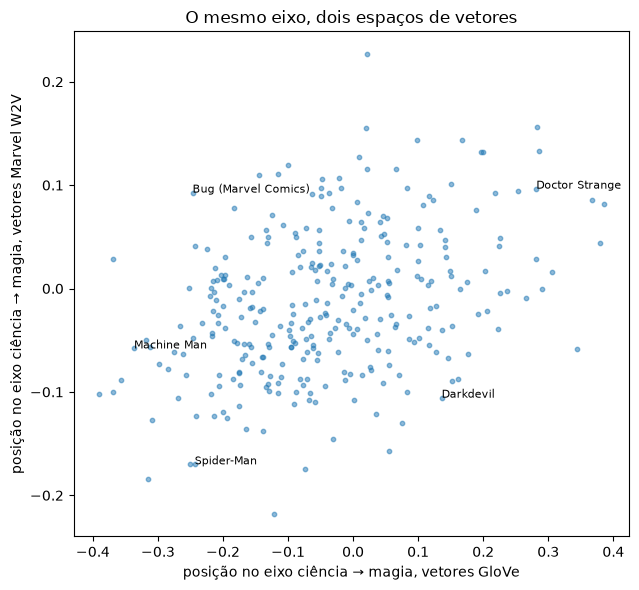

In [ ]:
# porque é que se mexem: as palavras da impressão digital e onde cada espaço as põe no eixo
def word_pos(kv, ws):
    pole = lambda ws_: np.mean([kv[w] / np.linalg.norm(kv[w]) for w in ws_ if w in kv], axis=0)
    axis = pole(MAGIC) - pole(SCIENCE); axis /= np.linalg.norm(axis)
    return {w: round(float(kv[w] @ axis / np.linalg.norm(kv[w])), 2) for w in ws if w in kv}
mv = both.reindex(both.move.abs().sort_values(ascending=False).index).index[:2]
inv = {v: k for k, v in name.items()}
for nm in mv:
    fp = [w for w, _ in fingerprint(IDS.index(inv[nm]), 10)]
    print(f"{nm}: impressão digital = {fp}")
    print("   GloVe :", word_pos(glove, fp)); print("   Marvel:", word_pos(w2v.wv, fp))

print("\npalavras de poderes mentais no eixo (positivo = lado da magia):")
print("   GloVe :", word_pos(glove, ["telepathic", "psychic", "telekinetic", "mind", "mutant"]))
print("   Marvel:", word_pos(w2v.wv, ["telepathic", "psychic", "telekinetic", "mind", "mutant"]))
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(both.GloVe, both.Marvel, s=10, alpha=0.5)
for nm in list(mv) + ["Doctor Strange", "Machine Man", "Spider-Man", "Iron Man"]:
    if nm in both.index: ax.annotate(nm, (both.loc[nm, "GloVe"], both.loc[nm, "Marvel"]), fontsize=8)
ax.set_xlabel("posição no eixo ciência → magia, vetores GloVe"); ax.set_ylabel("posição no eixo ciência → magia, vetores Marvel W2V")
ax.set_title("O mesmo eixo, dois espaços de vetores"); plt.tight_layout(); plt.savefig("figs/6.9_axis_glove_vs_marvel.png", dpi=150); plt.show()

**6.9.6 — O eixo ciência ↔ magia, com GloVe e com os vetores Marvel.** Impressão digital de cada personagem = as 20
palavras de maior TF-IDF da página, sem nomes (critério do 6.5) e sem stopwords, em média ponderada pelo TF-IDF;
polos: *magic, spell, sorcerer, mystic, magical, spells, sorcery, demon, supernatural* contra *science, technology,
experiment, scientist, scientific, laboratory, engineering, genetic, robot*.

- **Com GloVe** o eixo lê-se bem: polo **magia** = Satana, Black Knight, Balder the Brave, Werewolf by Night, Zombie,
  Blade (demónios, cavaleiros, deuses nórdicos, monstros); polo **ciência** = Stingray, Blue Marvel, Bill Foster, Machine
  Man, Vyking. Doctor Strange em 9.º do lado da magia, Machine Man em 299.º de 303.
- **Com os vetores Marvel** a correlação de posições com o GloVe é só **0.35** (Spearman). O polo **magia** passa a ser
  **Jean Grey, Emma Frost, Rachel Summers, Scarlet Witch, Betsy Braddock** — as **telepatas** das X-Men; Doctor Strange
  cai para 21.º. **Quem se mexe mais:** Bug (285 → 23), Darkdevil (40 → 281), Eddie Brock (31 → 264), Rikki Barnes
  (29 → 261).

**Porquê** (projeções das palavras no eixo, célula acima e uma inspeção à parte das impressões digitais):
(a) **As palavras de telepatia não são a diferença** — *telepathic, psychic, telekinetic* ficam ligeiramente do lado
da magia nos **dois** espaços (+0.12 a +0.19). (b) **A diferença está nas palavras genéricas e nos polos.** No GloVe as
palavras de magia são fortemente "magia" (*demon* +0.47, *spells* +0.43) e o vocabulário de escola/níveis das X-Men
(*school, students, level*) cai para o lado da ciência, por isso as telepatas ficam a meio. No espaço Marvel o próprio
polo é fraco (*demon* só +0.09, *spells* +0.09 — com 700 mil tokens os vetores das palavras-polo são ruidosos) e
palavras genéricas das páginas X-Men ficam do lado da "magia" (*mutants* +0.25, *cosmic* +0.24, *minds* +0.21) — no
texto Marvel, poderes mutantes e poderes místicos descrevem-se nas mesmas frases de "Powers and abilities". O eixo
Marvel passa a separar "páginas de poderes" de "páginas de tecnologia/ação", e as telepatas vão para o topo.
(c) Os **maiores saltos** são de páginas cuja impressão digital tem **poucas palavras no vocabulário Marvel**: para o
Bug, das 10 primeiras só *owned, toy, dated, rights* existem no Word2Vec (a página fala dos **direitos** do brinquedo
Micronauts — *"no longer held the publishing rights to the toy based characters"*), por isso quatro palavras sem
relação com o eixo decidem a posição; para o Darkdevil, *demonic* puxa para a magia no GloVe (+0.45) e é neutro no
Marvel (−0.04).

**Onde é que um eixo vai buscar o significado:** às **palavras-polo** que alguém escolheu **e** ao **espaço** onde se
medem — o mesmo par de listas, em dois espaços, dá dois mapas diferentes. O eixo não mede "ciência vs magia" das
personagens: mede como *estes textos* se posicionam em relação a *estas palavras* em *estes vetores*.

## Exercício 6.10 — Ship an explorable (🚀 builder, stretch, opcional)

> Pick one idea from the week that became clearer when you could see it and build the version you wish had been on this page. Agents encouraged; the explanation still has to be yours. [...] let a user change one TF-IDF document frequency and watch the weight move; build a cosine-angle playground; turn a pair of corpora into your own Scattertext-style comparison; let a user change the number of topics in a tiny topic model; show a context window becoming a word-context row; or make Skip-gram training pairs appear as the window moves.

Não feito aqui (é opcional e é um projeto de JavaScript à parte). **Sugestão com mais potencial de ensino, a partir
do que este notebook encontrou:** *"Hammer, o martelo e o vilão"* — uma janela deslizante sobre frases reais com
*hammer*/*Hammer*, um interruptor de lowercase e, ao lado, a linha palavra-contexto e os vizinhos PPMI a mudar.
Com lowercase a linha mistura Mjolnir e Hammer Industries (6.7.4); sem lowercase separa-se em dois. Mostra numa só
vista a janela (6.6.1), o PPMI (6.6.3) e o preço de uma escolha de pré-processamento.

## Exercício 6.11 — Go nuts with your LLM (🚀 builder, semanal)

> One free-form post on your group's site, link in this week's Teams channel by Monday evening, friendly criticism for at least one other group. [...] Use one of them to ask a question about the Marvel corpus that you actually want answered. One good question and one convincing figure beats five methods thrown together. Whatever you claim, inspect the text underneath it before you believe it.

Este notebook já tem as peças para várias das aberturas sugeridas:

- **Names or meaning?** — o 6.2.5/6.2.6 já mede, para cada par, que fração da semelhança vem de nomes (`proper`), de
  números (`2099`) e de fragmentos (`shi`, `ar`, `un`). Uma figura: para os 300 pares mais próximos, % da semelhança
  vinda de nomes vs ligados/não ligados na rede.
- **Who is textually close but structurally far away?** — `S_tfidf` e `G` já estão calculados; basta juntar
  `nx.shortest_path_length` e ordenar por cosseno alto + distância grande (Hawkeye × Hulk 2099 é o primeiro candidato).
- **Draw your own map** — `project()` do 6.9.6 aceita quaisquer polos e qualquer espaço; o eixo que "parecia
  promissor e era ruído" já está aqui: ciência ↔ magia nos vetores Marvel, que se enche de telepatas.

Ideia menos "segura", que saiu deste notebook: **"Quando o texto contradiz a rede"** — as páginas que o Louvain põe
numa comunidade mas cujo LDA/TF-IDF as põe noutra (Junior Juniper e Blue Bullet nas X-Men, 6.5.5). Uma figura só
(comunidade estrutural × tópico dominante) e a leitura das três páginas mais "deslocadas".
*(O post é para o site do grupo — fica por fazer por vocês.)*

## Wrap-up

- **6.1** — df 3/2/1 → idf 0 / 0.405 / 1.099; tfidf 0.058 / 0.058 / 0.157; cos(A,B) = 1, cos(A,C) = 0.707 (45°),
  cos(10A,B) = 1 porque a constante cancela.
- **6.2** — página igual à mão (cos D1–D2 0.214, D1–D3 0); `TfidfVectorizer`: tf bruta, idf suavizado **+1**, norma L2 →
  0.139; `smooth_idf=False` → 0.102; igual só subtraindo 1 ao `idf_`. 303 × 26 279; 10 termos com idf 0 (*marvel, comics*…);
  pares de topo = nomes (Eddie Brock × Venom 0.867); artefactos: `2099` (96%), `shi`/`ar`, `un`; Storm × Human Torch
  (87% *storm*); vizinhos ligados 1.8 / 2.8 / **4.0** / 0.3.
- **6.3** — X-Men vs Sobrenatural; diagonal = gramática; extremos = nomes; *mutant* real, *vampire* = 2 páginas,
  *fang* = Fin Fang Foom (94%); contar páginas em vez de usos: Spearman 0.83, saem os nomes de páginas compridas.
- **6.4** — φ (palavras | tópico) ≠ P(tópico | palavra); θ soma 1; etiqueta é minha; K é resolução, não verdade.
- **6.5** — sem filtro: tópicos-personagem; com filtro: mutantes, simbiontes, vampiros, combate + boilerplate de
  media (28%) + 1 incoerente; estáveis: mutantes, simbiontes, boilerplate; K=14 cria magia; X-Men 0.66 mutantes vs 0.25;
  Junior Juniper/Blue Bullet: a rede e o texto discordam; 20 Newsgroups funciona → a dificuldade está no corpus.
- **6.6** — janelas {puppy, the} / {the, puppy, the, ball}; PMI(dog,bark) = 1, (dog,the) = 0, (dog,money) = −1.32;
  hero: vizinho villain (0.963) → sidekick (0.920) com PPMI.
- **6.7** — 3 725 palavras, ±2; PMI(hammer,thor) = 5.59 conferido; PPMI limpa *hammer, symbiote, wife*; *hammer* ~
  *industries* = Justin Hammer fundido pelo lowercase; ±1 sintático, ±10 temático e ruidoso.
- **6.8** — 2 e 4 pares Skip-gram; CBOW {the, puppy, the, ball} → chased; custo |V| → k+1; relatório reescrito.
- **6.9** — W2V: *symbiote* ótimo, *hammer* com ruído de palavras raras (nunca na mesma frase); seed sozinha muda 3–6
  de 10 vizinhos; GloVe: *hammer* = ferramenta/atletismo, queen 0.770; eixo ciência ↔ magia: Spearman 0.35 entre
  espaços, no Marvel o polo magia enche-se de telepatas (polos fracos + vocabulário genérico de poderes).
- **6.10 / 6.11** — sugestões; por fazer no site do grupo.